In [1]:

import pandas as pd
import numpy as np

# Pakistan ODI Tri-Series 2026
# Initial match-level dataset

matches = {
    "match_id": [1, 2, 3, 4, 5, 6, 7],

    "date": [
        "2026-10-18",
        "2026-10-20",
        "2026-10-22",
        "2026-10-25",
        "2026-10-27",
        "2026-10-29",
        "2026-10-31"
    ],

    "venue": [
        "Rawalpindi Cricket Stadium",
        "Rawalpindi Cricket Stadium",
        "Rawalpindi Cricket Stadium",
        "Gaddafi Stadium",
        "Gaddafi Stadium",
        "Gaddafi Stadium",
        "Gaddafi Stadium"
    ],

    "team1": [
        "Pakistan",
        "Pakistan",
        "England",
        "England",
        "Pakistan",
        "England",
        "Sri Lanka"
    ],

    "team1_runs": [305, 302, 429, 241, 110, 386, 325],
    "team1_wickets": [10, 9, 4, 10, 10, 5, 8],
    "team1_overs": ["49.5", "50.0", "50.0", "46.4",
                    "25.3", "50.0", "50.0"],

    "team2": [
        "Sri Lanka",
        "England",
        "Sri Lanka",
        "Pakistan",
        "Sri Lanka",
        "Sri Lanka",
        "Pakistan"
    ],

    "team2_runs": [268, 215, 430, 243, 114, 331, 331],
    "team2_wickets": [10, 10, 8, 9, 2, 10, 7],
    "team2_overs": ["48.1", "38.4", "49.5", "47.1",
                    "18.1", "45.1", "48.3"],

    "winner": [
        "Pakistan",
        "Pakistan",
        "Sri Lanka",
        "Pakistan",
        "Sri Lanka",
        "England",
        "Pakistan"
    ]
}

df = pd.DataFrame(matches)

# Display the dataset
display(df)


,match_id,date,venue,team1,team1_runs,team1_wickets,team1_overs,team2,team2_runs,team2_wickets,team2_overs,winner
0,1,2026-10-18,Rawalpindi Cricket Stadium,Pakistan,305,10,49.5,Sri Lanka,268,10,48.1,Pakistan
1,2,2026-10-20,Rawalpindi Cricket Stadium,Pakistan,302,9,50.0,England,215,10,38.4,Pakistan
2,3,2026-10-22,Rawalpindi Cricket Stadium,England,429,4,50.0,Sri Lanka,430,8,49.5,Sri Lanka
3,4,2026-10-25,Gaddafi Stadium,England,241,10,46.4,Pakistan,243,9,47.1,Pakistan
4,5,2026-10-27,Gaddafi Stadium,Pakistan,110,10,25.3,Sri Lanka,114,2,18.1,Sri Lanka
5,6,2026-10-29,Gaddafi Stadium,England,386,5,50.0,Sri Lanka,331,10,45.1,England
6,7,2026-10-31,Gaddafi Stadium,Sri Lanka,325,8,50.0,Pakistan,331,7,48.3,Pakistan


In [2]:

# Dataset dimensions
print("Dataset dimensions:", df.shape)

# Column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types and missing values
print("\nDataset information:")
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Display first five matches
print("\nFirst five matches:")
display(df.head())


Dataset dimensions: (7, 12)

Column names:
['match_id', 'date', 'venue', 'team1', 'team1_runs', 'team1_wickets', 'team1_overs', 'team2', 'team2_runs', 'team2_wickets', 'team2_overs', 'winner']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7 entries, 0 to 6
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   match_id       7 non-null      int64 
 1   date           7 non-null      object
 2   venue          7 non-null      object
 3   team1          7 non-null      object
 4   team1_runs     7 non-null      int64 
 5   team1_wickets  7 non-null      int64 
 6   team1_overs    7 non-null      object
 7   team2          7 non-null      object
 8   team2_runs     7 non-null      int64 
 9   team2_wickets  7 non-null      int64 
 10  team2_overs    7 non-null      object
 11  winner         7 non-null      object
dtypes: int64(5), object(7)
memory usage: 804.0+ bytes

Missing values:
match_id  

,match_id,date,venue,team1,team1_runs,team1_wickets,team1_overs,team2,team2_runs,team2_wickets,team2_overs,winner
0,1,2026-10-18,Rawalpindi Cricket Stadium,Pakistan,305,10,49.5,Sri Lanka,268,10,48.1,Pakistan
1,2,2026-10-20,Rawalpindi Cricket Stadium,Pakistan,302,9,50.0,England,215,10,38.4,Pakistan
2,3,2026-10-22,Rawalpindi Cricket Stadium,England,429,4,50.0,Sri Lanka,430,8,49.5,Sri Lanka
3,4,2026-10-25,Gaddafi Stadium,England,241,10,46.4,Pakistan,243,9,47.1,Pakistan
4,5,2026-10-27,Gaddafi Stadium,Pakistan,110,10,25.3,Sri Lanka,114,2,18.1,Sri Lanka


In [3]:

# Create a team-level dataset

team1 = df[[
    "match_id", "date", "venue", "team1",
    "team1_runs", "team1_wickets", "winner"
]].copy()

team1.columns = [
    "match_id", "date", "venue", "team",
    "runs_scored", "wickets_lost", "winner"
]

team2 = df[[
    "match_id", "date", "venue", "team2",
    "team2_runs", "team2_wickets", "winner"
]].copy()

team2.columns = [
    "match_id", "date", "venue", "team",
    "runs_scored", "wickets_lost", "winner"
]

# Combine both teams
team_data = pd.concat([team1, team2], ignore_index=True)

# Identify winning teams
team_data["result"] = np.where(
    team_data["team"] == team_data["winner"],
    "Won",
    "Lost"
)

# Display the new dataset
display(team_data)


,match_id,date,venue,team,runs_scored,wickets_lost,winner,result
0,1,2026-10-18,Rawalpindi Cricket Stadium,Pakistan,305,10,Pakistan,Won
1,2,2026-10-20,Rawalpindi Cricket Stadium,Pakistan,302,9,Pakistan,Won
2,3,2026-10-22,Rawalpindi Cricket Stadium,England,429,4,Sri Lanka,Lost
3,4,2026-10-25,Gaddafi Stadium,England,241,10,Pakistan,Lost
4,5,2026-10-27,Gaddafi Stadium,Pakistan,110,10,Sri Lanka,Lost
5,6,2026-10-29,Gaddafi Stadium,England,386,5,England,Won
6,7,2026-10-31,Gaddafi Stadium,Sri Lanka,325,8,Pakistan,Lost
7,1,2026-10-18,Rawalpindi Cricket Stadium,Sri Lanka,268,10,Pakistan,Lost
8,2,2026-10-20,Rawalpindi Cricket Stadium,England,215,10,Pakistan,Lost
9,3,2026-10-22,Rawalpindi Cricket Stadium,Sri Lanka,430,8,Sri Lanka,Won


In [4]:

# Calculate overall team performance

team_summary = team_data.groupby("team").agg(
    matches_played=("match_id", "count"),
    matches_won=("result", lambda x: (x == "Won").sum()),
    total_runs=("runs_scored", "sum"),
    average_runs=("runs_scored", "mean"),
    highest_total=("runs_scored", "max"),
    average_wickets_lost=("wickets_lost", "mean")
).reset_index()

# Calculate win percentage
team_summary["win_percentage"] = (
    team_summary["matches_won"] /
    team_summary["matches_played"] * 100
)

# Round decimal values
team_summary = team_summary.round(2)

# Sort teams by wins
team_summary = team_summary.sort_values(
    by="matches_won",
    ascending=False
)

display(team_summary)


,team,matches_played,matches_won,total_runs,average_runs,highest_total,average_wickets_lost,win_percentage
1,Pakistan,5,4,1291,258.20,331,9.00,80.0
2,Sri Lanka,5,2,1468,293.60,430,7.60,40.0
0,England,4,1,1271,317.75,429,7.25,25.0


In [5]:

# Convert cricket overs into legal balls

def overs_to_balls(overs):
    whole, balls = str(overs).split(".")
    return int(whole) * 6 + int(balls)

# Rebuild team data with overs included

team1 = df[[
    "match_id", "date", "venue", "team1",
    "team1_runs", "team1_wickets",
    "team1_overs", "winner"
]].copy()

team1.columns = [
    "match_id", "date", "venue", "team",
    "runs_scored", "wickets_lost",
    "overs", "winner"
]

team2 = df[[
    "match_id", "date", "venue", "team2",
    "team2_runs", "team2_wickets",
    "team2_overs", "winner"
]].copy()

team2.columns = [
    "match_id", "date", "venue", "team",
    "runs_scored", "wickets_lost",
    "overs", "winner"
]

team_data = pd.concat([team1, team2], ignore_index=True)

team_data["balls_faced"] = team_data["overs"].apply(overs_to_balls)

team_data["run_rate"] = (
    team_data["runs_scored"] /
    team_data["balls_faced"] * 6
)

team_data["result"] = np.where(
    team_data["team"] == team_data["winner"],
    "Won",
    "Lost"
)

# Separate group-stage matches from the final
team_data["stage"] = np.where(
    team_data["match_id"] == 7,
    "Final",
    "Group Stage"
)

display(team_data)


,match_id,date,venue,team,runs_scored,wickets_lost,overs,winner,balls_faced,run_rate,result,stage
0,1,2026-10-18,Rawalpindi Cricket Stadium,Pakistan,305,10,49.5,Pakistan,299,6.120401,Won,Group Stage
1,2,2026-10-20,Rawalpindi Cricket Stadium,Pakistan,302,9,50.0,Pakistan,300,6.040000,Won,Group Stage
2,3,2026-10-22,Rawalpindi Cricket Stadium,England,429,4,50.0,Sri Lanka,300,8.580000,Lost,Group Stage
3,4,2026-10-25,Gaddafi Stadium,England,241,10,46.4,Pakistan,280,5.164286,Lost,Group Stage
4,5,2026-10-27,Gaddafi Stadium,Pakistan,110,10,25.3,Sri Lanka,153,4.313725,Lost,Group Stage
5,6,2026-10-29,Gaddafi Stadium,England,386,5,50.0,England,300,7.720000,Won,Group Stage
6,7,2026-10-31,Gaddafi Stadium,Sri Lanka,325,8,50.0,Pakistan,300,6.500000,Lost,Final
7,1,2026-10-18,Rawalpindi Cricket Stadium,Sri Lanka,268,10,48.1,Pakistan,289,5.564014,Lost,Group Stage
8,2,2026-10-20,Rawalpindi Cricket Stadium,England,215,10,38.4,Pakistan,232,5.560345,Lost,Group Stage
9,3,2026-10-22,Rawalpindi Cricket Stadium,Sri Lanka,430,8,49.5,Sri Lanka,299,8.628763,Won,Group Stage


In [7]:

# Group-stage performance
group_data = team_data[
    team_data["stage"] == "Group Stage"
].copy()

group_summary = group_data.groupby("team").agg(
    matches=("match_id", "count"),
    wins=("result", lambda x: (x == "Won").sum()),
    total_runs=("runs_scored", "sum"),
    average_runs=("runs_scored", "mean"),
    highest_score=("runs_scored", "max"),
    average_run_rate=("run_rate", "mean")
).reset_index()

group_summary["win_percentage"] = (
    group_summary["wins"] /
    group_summary["matches"] * 100
)

display(group_summary.round(2))


,team,matches,wins,total_runs,average_runs,highest_score,average_run_rate,win_percentage
0,England,4,1,1271,317.75,429,6.76,25.0
1,Pakistan,4,3,960,240.00,305,5.41,75.0
2,Sri Lanka,4,2,1143,285.75,430,6.95,50.0


In [8]:

overall_summary = team_data.groupby("team").agg(
    matches=("match_id", "count"),
    wins=("result", lambda x: (x == "Won").sum()),
    losses=("result", lambda x: (x == "Lost").sum()),
    average_runs=("runs_scored", "mean"),
    highest_score=("runs_scored", "max"),
    average_wickets_lost=("wickets_lost", "mean"),
    average_run_rate=("run_rate", "mean")
).reset_index()

overall_summary["win_percentage"] = (
    overall_summary["wins"] /
    overall_summary["matches"] * 100
)

display(overall_summary.round(2))


,team,matches,wins,losses,average_runs,highest_score,average_wickets_lost,average_run_rate,win_percentage
0,England,4,1,3,317.75,429,7.25,6.76,25.0
1,Pakistan,5,4,1,258.20,331,9.00,5.69,80.0
2,Sri Lanka,5,2,3,293.60,430,7.60,6.86,40.0


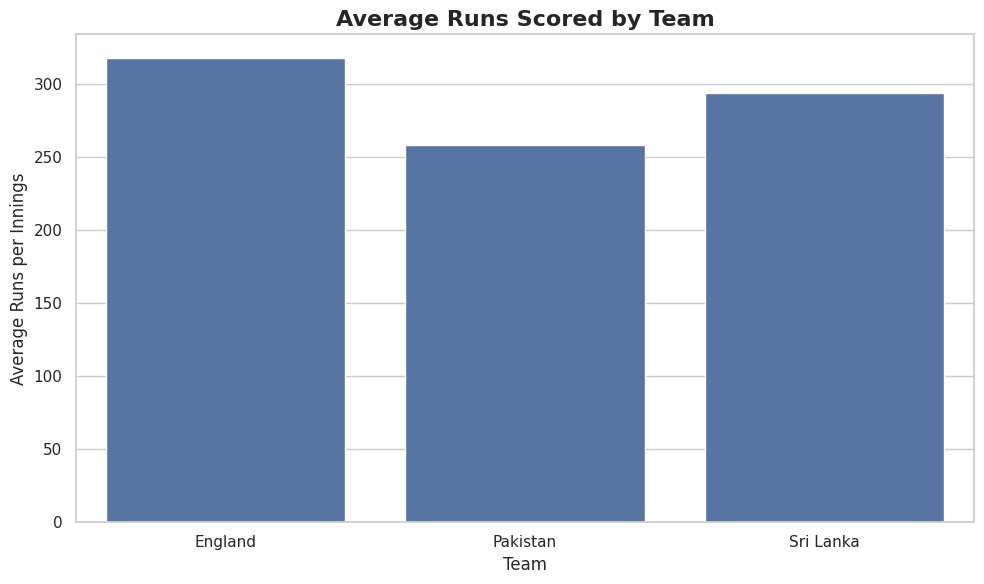

In [9]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

sns.barplot(
    data=overall_summary,
    x="team",
    y="average_runs"
)

plt.title(
    "Average Runs Scored by Team",
    fontsize=16,
    weight="bold"
)

plt.xlabel("Team")
plt.ylabel("Average Runs per Innings")

plt.tight_layout()
plt.savefig("average_team_runs.png", dpi=300)
plt.show()


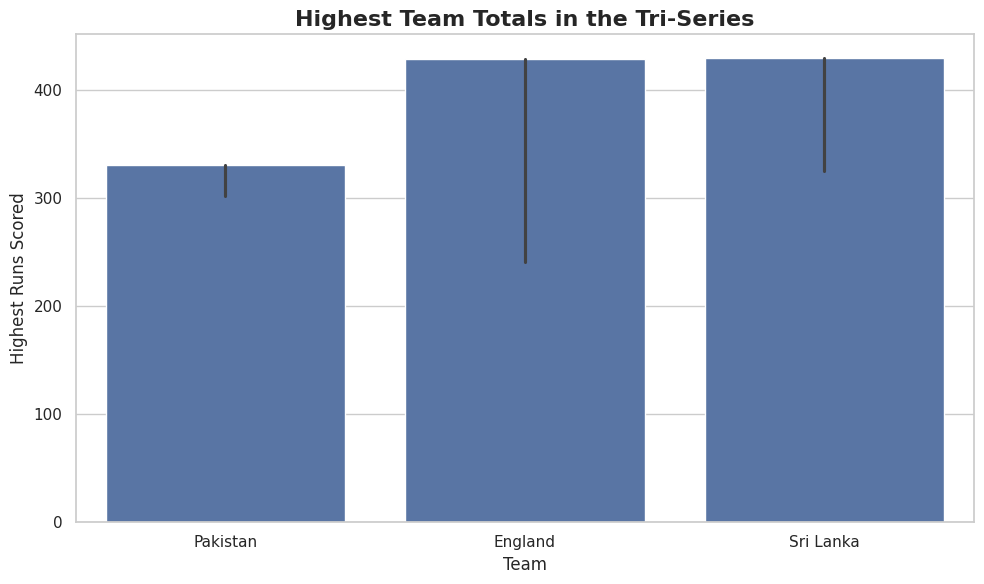

In [10]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=team_data,
    x="team",
    y="runs_scored",
    estimator=max
)

plt.title(
    "Highest Team Totals in the Tri-Series",
    fontsize=16,
    weight="bold"
)

plt.xlabel("Team")
plt.ylabel("Highest Runs Scored")

plt.tight_layout()
plt.savefig("highest_team_totals.png", dpi=300)
plt.show()


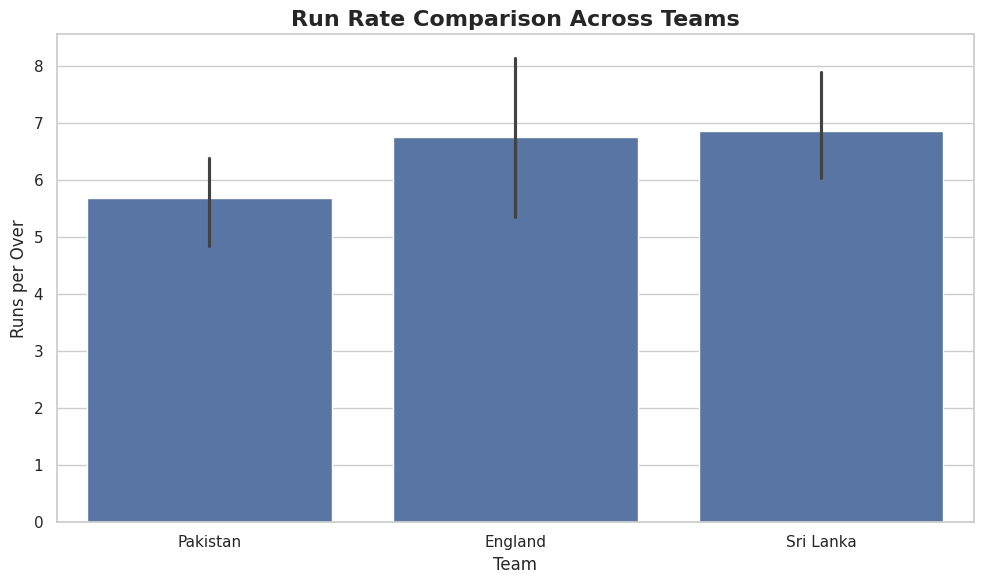

In [11]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=team_data,
    x="team",
    y="run_rate"
)

plt.title(
    "Run Rate Comparison Across Teams",
    fontsize=16,
    weight="bold"
)

plt.xlabel("Team")
plt.ylabel("Runs per Over")

plt.tight_layout()
plt.savefig("team_run_rates.png", dpi=300)
plt.show()


In [12]:

venue_summary = team_data.groupby("venue").agg(
    innings=("match_id", "count"),
    average_score=("runs_scored", "mean"),
    highest_score=("runs_scored", "max"),
    average_run_rate=("run_rate", "mean"),
    average_wickets_lost=("wickets_lost", "mean")
).reset_index()

display(venue_summary.round(2))


,venue,innings,average_score,highest_score,average_run_rate,average_wickets_lost
0,Gaddafi Stadium,8,260.12,386,6.16,7.62
1,Rawalpindi Cricket Stadium,6,324.83,430,6.75,8.50


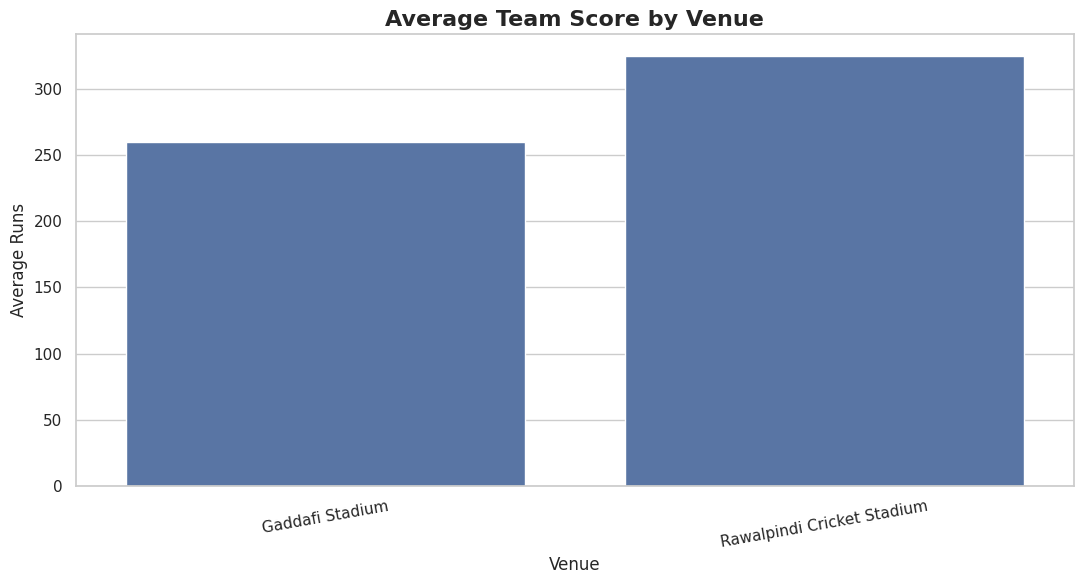

In [13]:

plt.figure(figsize=(11, 6))

sns.barplot(
    data=venue_summary,
    x="venue",
    y="average_score"
)

plt.title(
    "Average Team Score by Venue",
    fontsize=16,
    weight="bold"
)

plt.xlabel("Venue")
plt.ylabel("Average Runs")

plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig("venue_comparison.png", dpi=300)
plt.show()


In [14]:

# Final match figures

target = 326
pakistan_runs = 331
pakistan_balls = 48 * 6 + 3
total_balls = 50 * 6

runs_required = target - 1
runs_scored = pakistan_runs

required_run_rate = (
    runs_required / total_balls * 6
)

actual_run_rate = (
    runs_scored / pakistan_balls * 6
)

balls_remaining = total_balls - pakistan_balls
wickets_remaining = 10 - 7

print("Target:", target)
print("Pakistan's final score:", pakistan_runs)
print("Runs required before the chase:", runs_required)
print("Required run rate:", round(required_run_rate, 2))
print("Actual run rate:", round(actual_run_rate, 2))
print("Balls remaining:", balls_remaining)
print("Wickets remaining:", wickets_remaining)


Target: 326
Pakistan's final score: 331
Runs required before the chase: 325
Required run rate: 6.5
Actual run rate: 6.82
Balls remaining: 9
Wickets remaining: 3


In [15]:

final_batting = pd.DataFrame({
    "player": [
        "Fakhar Zaman",
        "Saad Baig",
        "Arafat Minhas",
        "Hasan Nawaz",
        "Kamindu Mendis",
        "Pavan Rathnayake"
    ],

    "team": [
        "Pakistan",
        "Pakistan",
        "Pakistan",
        "Pakistan",
        "Sri Lanka",
        "Sri Lanka"
    ],

    "runs": [127, 74, 61, 37, 131, 77],

    "balls": [99, 75, 31, 45, 128, 65]
})

final_batting["strike_rate"] = (
    final_batting["runs"] /
    final_batting["balls"] * 100
)

display(final_batting.round(2))


,player,team,runs,balls,strike_rate
0,Fakhar Zaman,Pakistan,127,99,128.28
1,Saad Baig,Pakistan,74,75,98.67
2,Arafat Minhas,Pakistan,61,31,196.77
3,Hasan Nawaz,Pakistan,37,45,82.22
4,Kamindu Mendis,Sri Lanka,131,128,102.34
5,Pavan Rathnayake,Sri Lanka,77,65,118.46


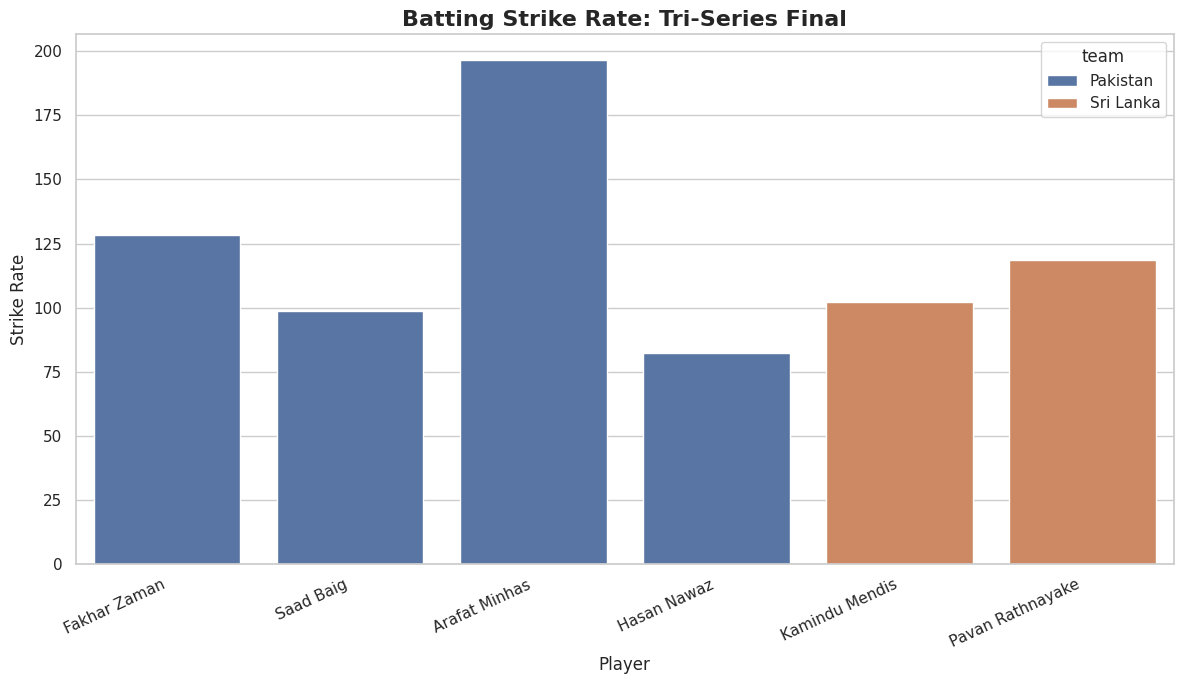

In [16]:

plt.figure(figsize=(12, 7))

sns.barplot(
    data=final_batting,
    x="player",
    y="strike_rate",
    hue="team"
)

plt.title(
    "Batting Strike Rate: Tri-Series Final",
    fontsize=16,
    weight="bold"
)

plt.xlabel("Player")
plt.ylabel("Strike Rate")

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig("final_batting_strike_rates.png", dpi=300)
plt.show()


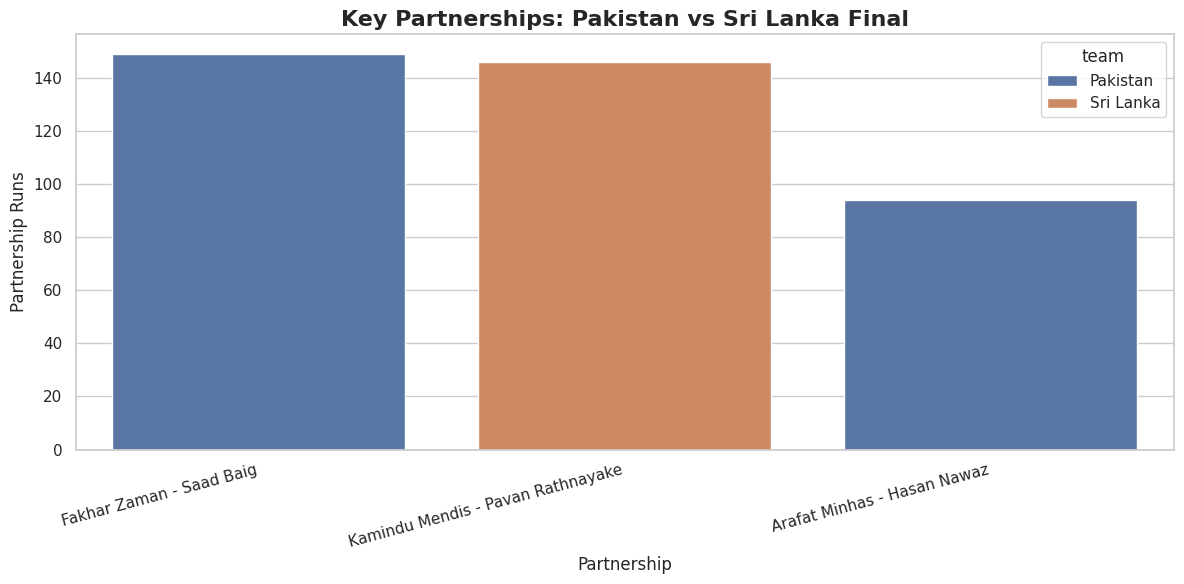

In [17]:

partnerships = pd.DataFrame({
    "partnership": [
        "Fakhar Zaman - Saad Baig",
        "Kamindu Mendis - Pavan Rathnayake",
        "Arafat Minhas - Hasan Nawaz"
    ],

    "team": [
        "Pakistan",
        "Sri Lanka",
        "Pakistan"
    ],

    "runs": [149, 146, 94]
})

plt.figure(figsize=(12, 6))

sns.barplot(
    data=partnerships,
    x="partnership",
    y="runs",
    hue="team"
)

plt.title(
    "Key Partnerships: Pakistan vs Sri Lanka Final",
    fontsize=16,
    weight="bold"
)

plt.xlabel("Partnership")
plt.ylabel("Partnership Runs")

plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.savefig("final_partnerships.png", dpi=300)
plt.show()


In [18]:

final_bowling = pd.DataFrame({
    "bowler": [
        "Salman Ali Agha",
        "Shaheen Shah Afridi",
        "Haris Rauf",
        "Naseem Shah"
    ],

    "wickets": [2, 2, 2, 2],

    "runs_conceded": [44, 50, 60, 80]
})

display(final_bowling)


,bowler,wickets,runs_conceded
0,Salman Ali Agha,2,44
1,Shaheen Shah Afridi,2,50
2,Haris Rauf,2,60
3,Naseem Shah,2,80


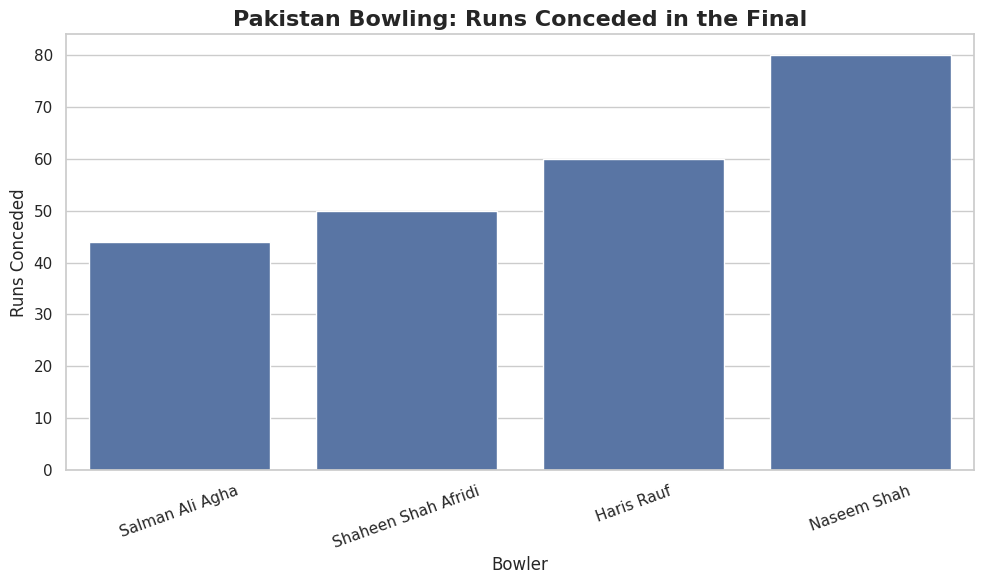

In [19]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=final_bowling,
    x="bowler",
    y="runs_conceded"
)

plt.title(
    "Pakistan Bowling: Runs Conceded in the Final",
    fontsize=16,
    weight="bold"
)

plt.xlabel("Bowler")
plt.ylabel("Runs Conceded")

plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("final_bowling_performance.png", dpi=300)
plt.show()


In [20]:

batting_template = pd.DataFrame(columns=[
    "match_id",
    "date",
    "team",
    "player",
    "runs",
    "balls",
    "fours",
    "sixes",
    "dismissal"
])

batting_template.to_csv(
    "tri_series_batting_template.csv",
    index=False
)

display(batting_template)


,match_id,date,team,player,runs,balls,fours,sixes,dismissal


In [21]:

bowling_template = pd.DataFrame(columns=[
    "match_id",
    "date",
    "team",
    "bowler",
    "overs",
    "maidens",
    "runs_conceded",
    "wickets",
    "wides",
    "no_balls"
])

bowling_template.to_csv(
    "tri_series_bowling_template.csv",
    index=False
)

display(bowling_template)

bowling_template = pd.DataFrame(columns=[
    "match_id",
    "date",
    "team",
    "bowler",
    "overs",
    "maidens",
    "runs_conceded",
    "wickets",
    "wides",
    "no_balls"
])

bowling_template.to_csv(
    "tri_series_bowling_template.csv",
    index=False
)

display(bowling_template)


,match_id,date,team,bowler,overs,maidens,runs_conceded,wickets,wides,no_balls


,match_id,date,team,bowler,overs,maidens,runs_conceded,wickets,wides,no_balls


In [22]:

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import os

# Create a folder for professional visuals
os.makedirs("professional_visuals", exist_ok=True)

# Professional cricket analytics colour palette
COLORS = {
    "Pakistan": "#00D68F",
    "England": "#FF914D",
    "Sri Lanka": "#38BDF8"
}

BG = "#080F1C"
PANEL = "#111C2E"
WHITE = "#F1F5F9"
MUTED = "#94A3B8"
GRID = "#27364A"

# Global chart settings
plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": PANEL,
    "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "text.color": WHITE,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.titleweight": "bold",
    "savefig.facecolor": BG,
    "savefig.dpi": 300
})

def style_axis(ax):
    ax.set_facecolor(PANEL)
    ax.grid(axis="x", color=GRID, alpha=0.55, linewidth=0.7)
    ax.set_axisbelow(True)

    for spine in ax.spines.values():
        spine.set_visible(False)

print("Professional cricket visual theme activated.")


Professional cricket visual theme activated.


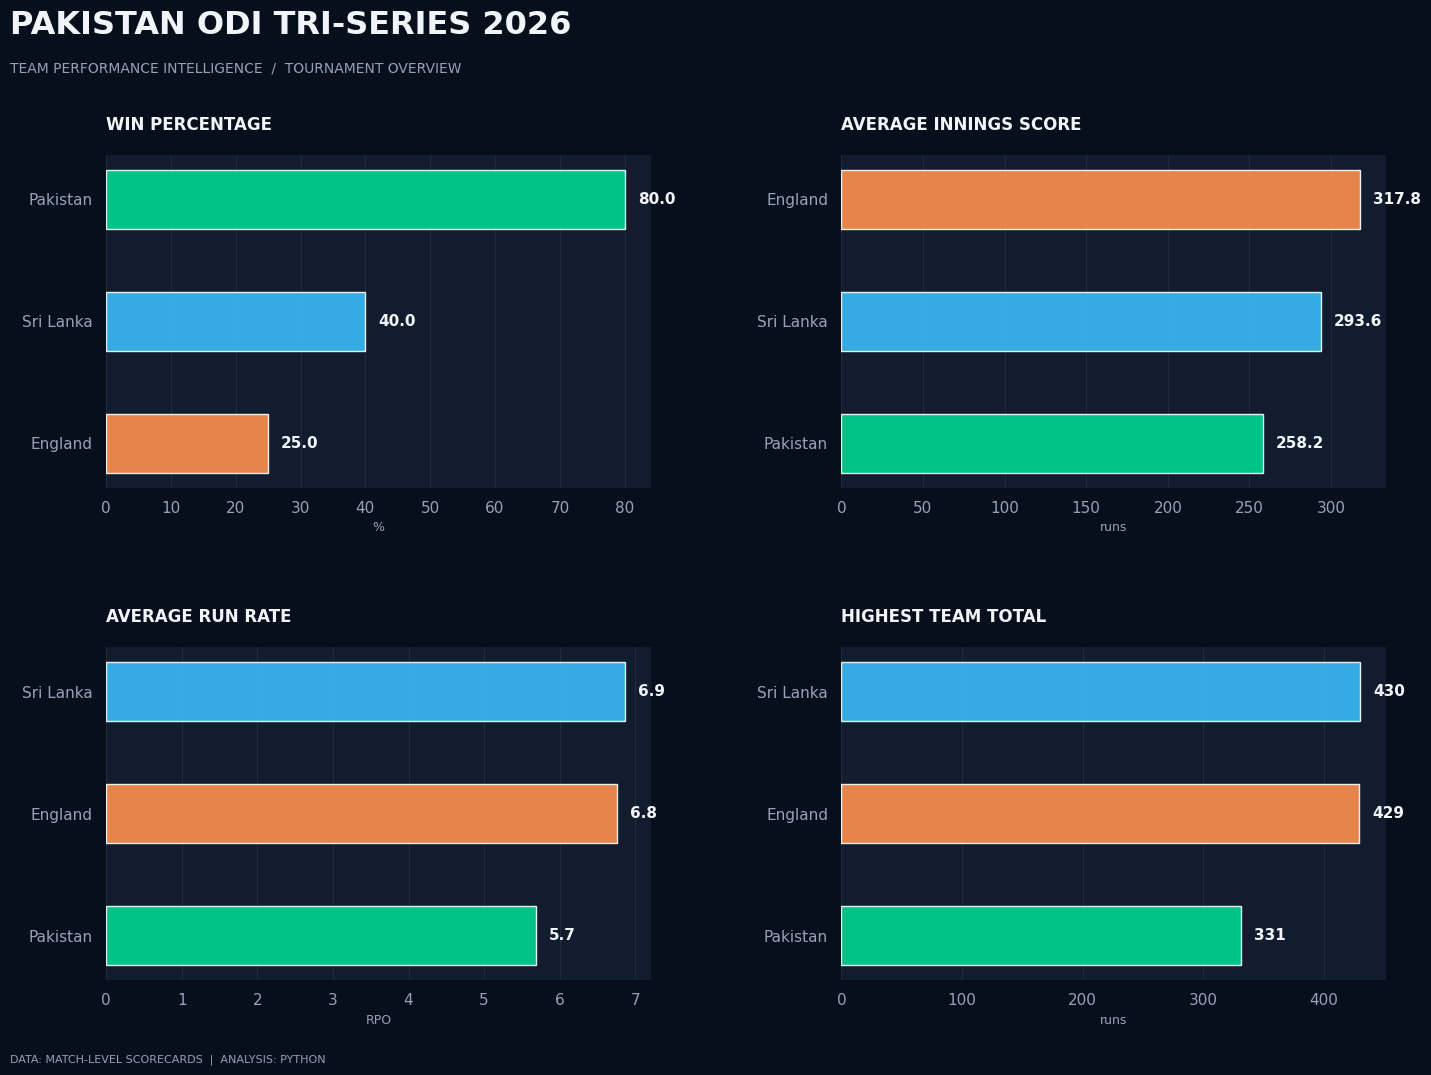

In [23]:

# MAIN TOURNAMENT PERFORMANCE DASHBOARD

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

fig.patch.set_facecolor(BG)

fig.text(
    0.07, 0.96,
    "PAKISTAN ODI TRI-SERIES 2026",
    fontsize=23,
    fontweight="bold",
    color=WHITE
)

fig.text(
    0.07, 0.925,
    "TEAM PERFORMANCE INTELLIGENCE  /  TOURNAMENT OVERVIEW",
    fontsize=10,
    color=MUTED
)

metrics = [
    ("win_percentage", "WIN PERCENTAGE", "%"),
    ("average_runs", "AVERAGE INNINGS SCORE", "runs"),
    ("average_run_rate", "AVERAGE RUN RATE", "RPO"),
    ("highest_score", "HIGHEST TEAM TOTAL", "runs")
]

for ax, (metric, heading, unit) in zip(axes.flat, metrics):

    style_axis(ax)

    plot_data = overall_summary.sort_values(metric)

    teams = plot_data["team"].tolist()
    values = plot_data[metric].tolist()

    colors = [COLORS[t] for t in teams]

    bars = ax.barh(
        teams,
        values,
        color=colors,
        height=0.48,
        alpha=0.9
    )

    ax.set_title(
        heading,
        loc="left",
        fontsize=12,
        fontweight="bold",
        color=WHITE,
        pad=18
    )

    ax.set_xlabel(unit, fontsize=9)

    ax.xaxis.grid(True, color=GRID, alpha=0.6)
    ax.yaxis.grid(False)

    for bar, value in zip(bars, values):

        ax.text(
            bar.get_width() + max(values) * 0.025,
            bar.get_y() + bar.get_height()/2,
            f"{value:.1f}" if isinstance(value, (float, np.floating)) else str(value),
            va="center",
            fontsize=11,
            fontweight="bold",
            color=WHITE
        )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

plt.subplots_adjust(
    left=0.13,
    right=0.93,
    top=0.85,
    bottom=0.10,
    hspace=0.48,
    wspace=0.35
)

fig.text(
    0.07, 0.025,
    "DATA: MATCH-LEVEL SCORECARDS  |  ANALYSIS: PYTHON",
    fontsize=8,
    color=MUTED
)

plt.savefig(
    "professional_visuals/01_team_performance_dashboard.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


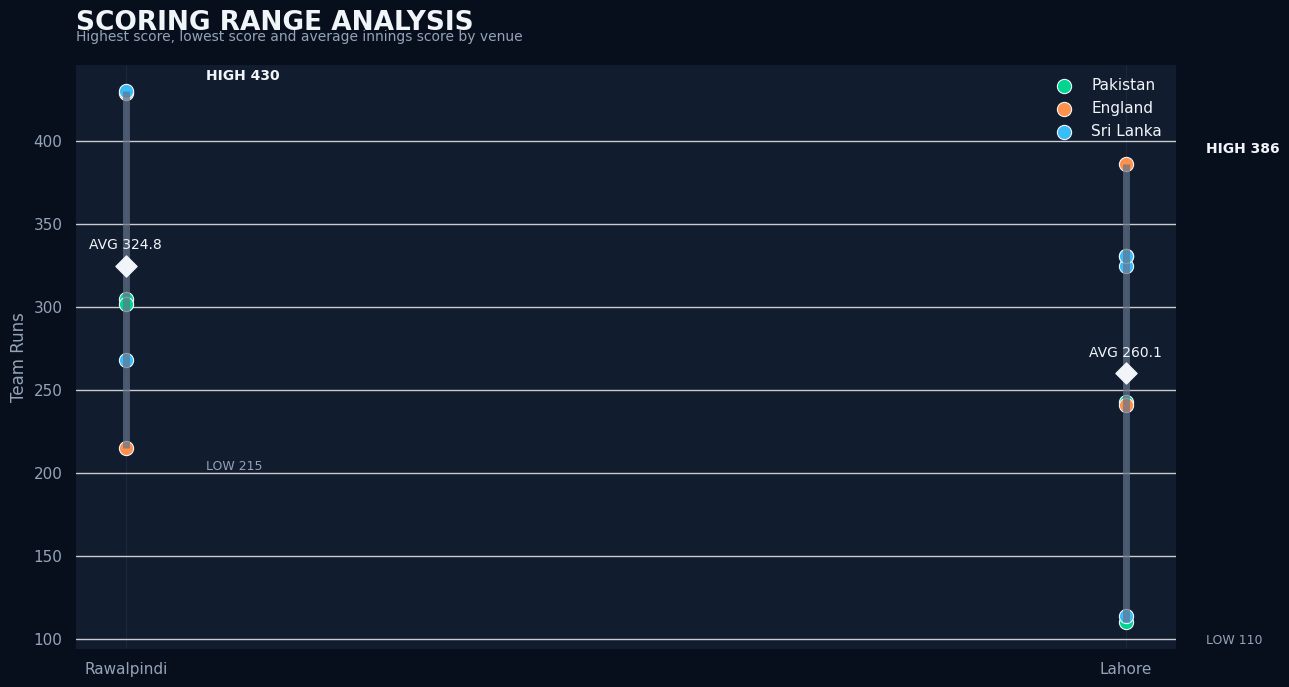

In [24]:

# HIGH-LOW TEAM SCORING ANALYSIS

fig, ax = plt.subplots(figsize=(13, 7))

style_axis(ax)

venues = team_data["venue"].unique()

for i, venue in enumerate(venues):

    subset = team_data[team_data["venue"] == venue]

    scores = subset["runs_scored"]

    low = scores.min()
    high = scores.max()
    average = scores.mean()

    # Vertical high-low range
    ax.vlines(
        i,
        low,
        high,
        color="#64748B",
        linewidth=5,
        alpha=0.7
    )

    # Individual innings observations
    for team in COLORS:

        team_scores = subset[
            subset["team"] == team
        ]["runs_scored"]

        if len(team_scores) > 0:

            ax.scatter(
                [i] * len(team_scores),
                team_scores,
                color=COLORS[team],
                s=105,
                edgecolors=WHITE,
                linewidths=0.8,
                label=team
            )

    # Average score marker
    ax.scatter(
        i,
        average,
        marker="D",
        color=WHITE,
        s=115,
        zorder=5
    )

    ax.text(
        i + 0.08,
        high + 7,
        f"HIGH {high}",
        color=WHITE,
        fontsize=10,
        fontweight="bold"
    )

    ax.text(
        i + 0.08,
        low - 13,
        f"LOW {low}",
        color=MUTED,
        fontsize=9
    )

    ax.text(
        i,
        average + 10,
        f"AVG {average:.1f}",
        color=WHITE,
        fontsize=10,
        ha="center"
    )

ax.set_xticks(range(len(venues)))

ax.set_xticklabels([
    "Rawalpindi",
    "Lahore"
])

ax.set_ylabel("Team Runs")
ax.set_title(
    "SCORING RANGE ANALYSIS",
    loc="left",
    fontsize=19,
    pad=25
)

ax.text(
    0,
    1.04,
    "Highest score, lowest score and average innings score by venue",
    transform=ax.transAxes,
    color=MUTED,
    fontsize=10
)

handles, labels = ax.get_legend_handles_labels()

unique = dict(zip(labels, handles))

ax.legend(
    unique.values(),
    unique.keys(),
    loc="upper right",
    frameon=False,
    labelcolor=WHITE
)

plt.tight_layout()

plt.savefig(
    "professional_visuals/02_high_low_scoring.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


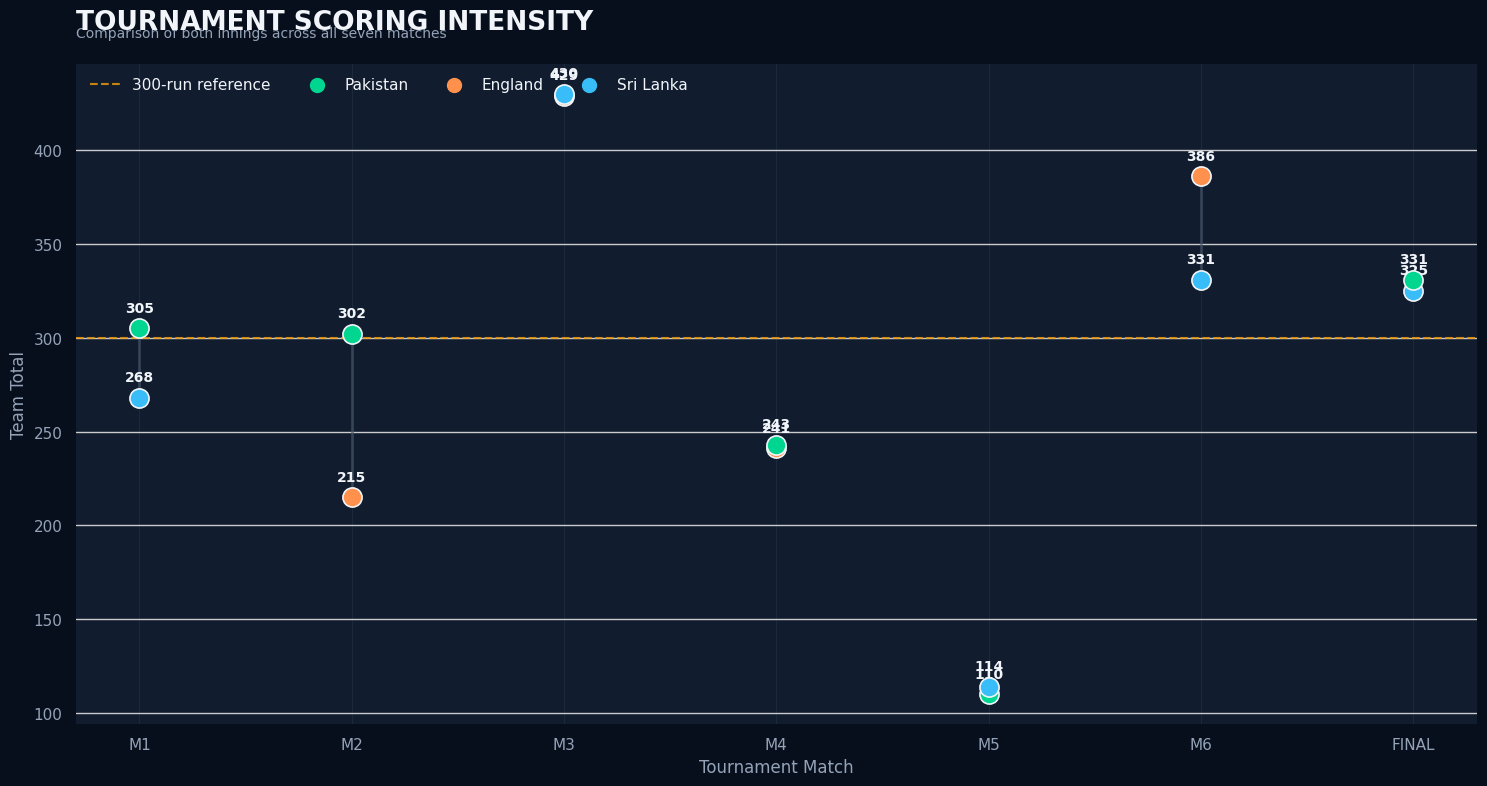

In [25]:

# MATCH-BY-MATCH SCORE PROFILE

fig, ax = plt.subplots(figsize=(15, 8))

style_axis(ax)

for match_id in sorted(team_data["match_id"].unique()):

    match = team_data[
        team_data["match_id"] == match_id
    ]

    # Connect both innings of each match
    if len(match) == 2:

        scores = match["runs_scored"].tolist()

        ax.plot(
            [match_id, match_id],
            scores,
            color="#475569",
            linewidth=2,
            alpha=0.65,
            zorder=1
        )

    for _, row in match.iterrows():

        team = row["team"]
        score = row["runs_scored"]

        ax.scatter(
            match_id,
            score,
            s=190,
            color=COLORS[team],
            edgecolors=WHITE,
            linewidths=1.2,
            zorder=3
        )

        ax.annotate(
            str(score),
            (match_id, score),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            color=WHITE,
            fontsize=10,
            fontweight="bold"
        )

ax.axhline(
    300,
    color="#F59E0B",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    label="300-run reference"
)

ax.set_xticks(range(1, 8))

ax.set_xticklabels([
    "M1", "M2", "M3", "M4", "M5", "M6", "FINAL"
])

ax.set_xlabel("Tournament Match")
ax.set_ylabel("Team Total")

ax.set_title(
    "TOURNAMENT SCORING INTENSITY",
    loc="left",
    fontsize=19,
    pad=25
)

ax.text(
    0,
    1.04,
    "Comparison of both innings across all seven matches",
    transform=ax.transAxes,
    color=MUTED,
    fontsize=10
)

for team, color in COLORS.items():

    ax.scatter(
        [], [],
        color=color,
        s=100,
        label=team
    )

ax.legend(
    loc="upper left",
    frameon=False,
    labelcolor=WHITE,
    ncol=4
)

plt.tight_layout()

plt.savefig(
    "professional_visuals/03_match_scoring_profile.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


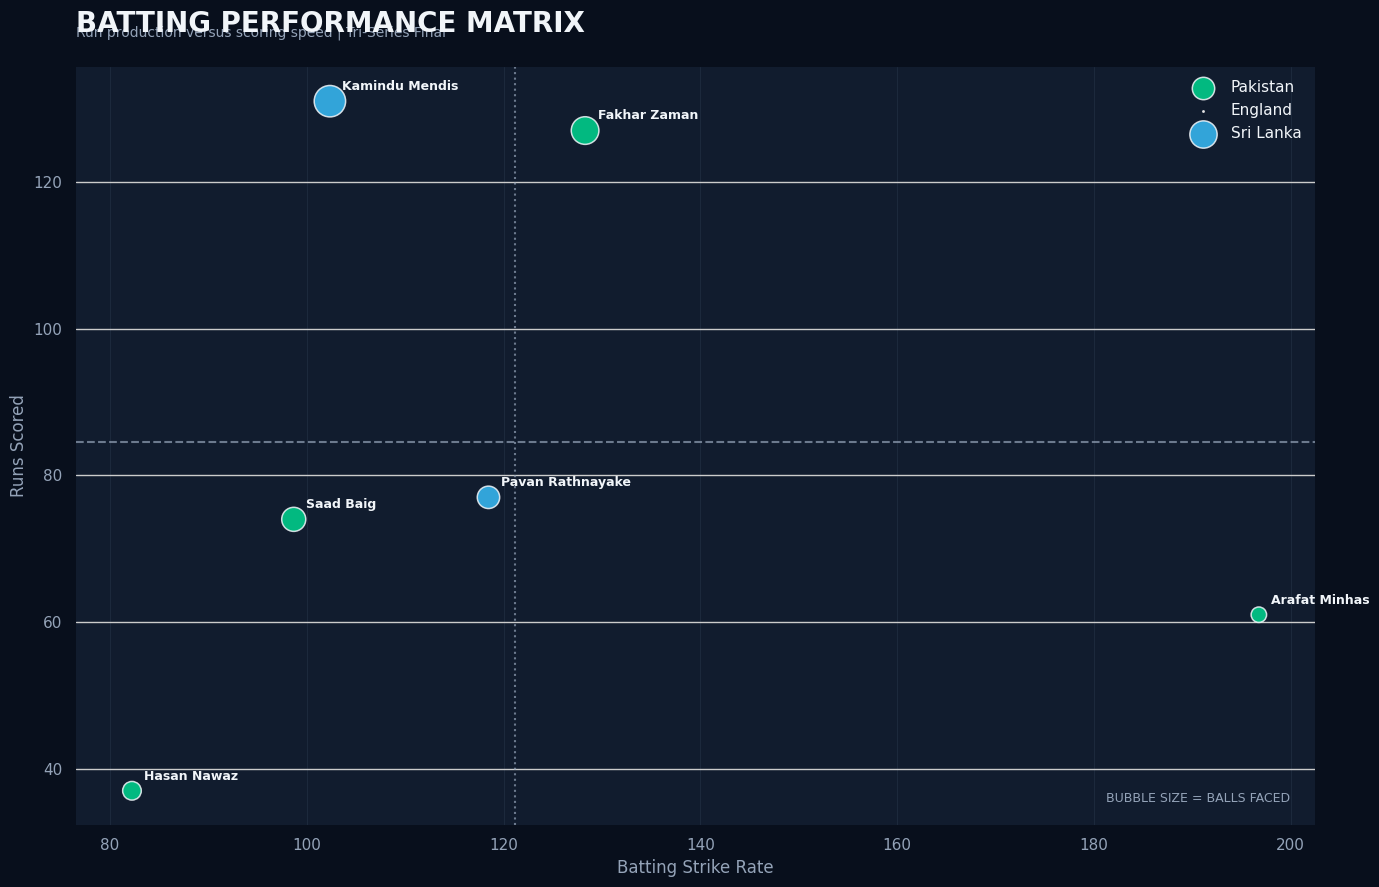

In [26]:

# FINAL MATCH: BATTER PERFORMANCE MAP

fig, ax = plt.subplots(figsize=(14, 9))

style_axis(ax)

for team in COLORS:

    subset = final_batting[
        final_batting["team"] == team
    ]

    ax.scatter(
        subset["strike_rate"],
        subset["runs"],
        s=subset["balls"] * 4,
        color=COLORS[team],
        alpha=0.85,
        edgecolors=WHITE,
        linewidths=1.1,
        label=team,
        zorder=3
    )

    for _, player in subset.iterrows():

        ax.annotate(
            player["player"],
            (
                player["strike_rate"],
                player["runs"]
            ),
            xytext=(9, 8),
            textcoords="offset points",
            fontsize=9,
            color=WHITE,
            fontweight="bold"
        )

# Reference lines
ax.axhline(
    final_batting["runs"].mean(),
    color=MUTED,
    linestyle="--",
    alpha=0.7
)

ax.axvline(
    final_batting["strike_rate"].mean(),
    color=MUTED,
    linestyle=":",
    alpha=0.7
)

ax.set_title(
    "BATTING PERFORMANCE MATRIX",
    loc="left",
    fontsize=20,
    pad=25
)

ax.text(
    0,
    1.04,
    "Run production versus scoring speed | Tri-Series Final",
    transform=ax.transAxes,
    color=MUTED,
    fontsize=10
)

ax.set_xlabel("Batting Strike Rate")
ax.set_ylabel("Runs Scored")

ax.legend(
    frameon=False,
    labelcolor=WHITE
)

ax.text(
    0.98,
    0.03,
    "BUBBLE SIZE = BALLS FACED",
    transform=ax.transAxes,
    ha="right",
    color=MUTED,
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    "professional_visuals/04_batting_performance_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


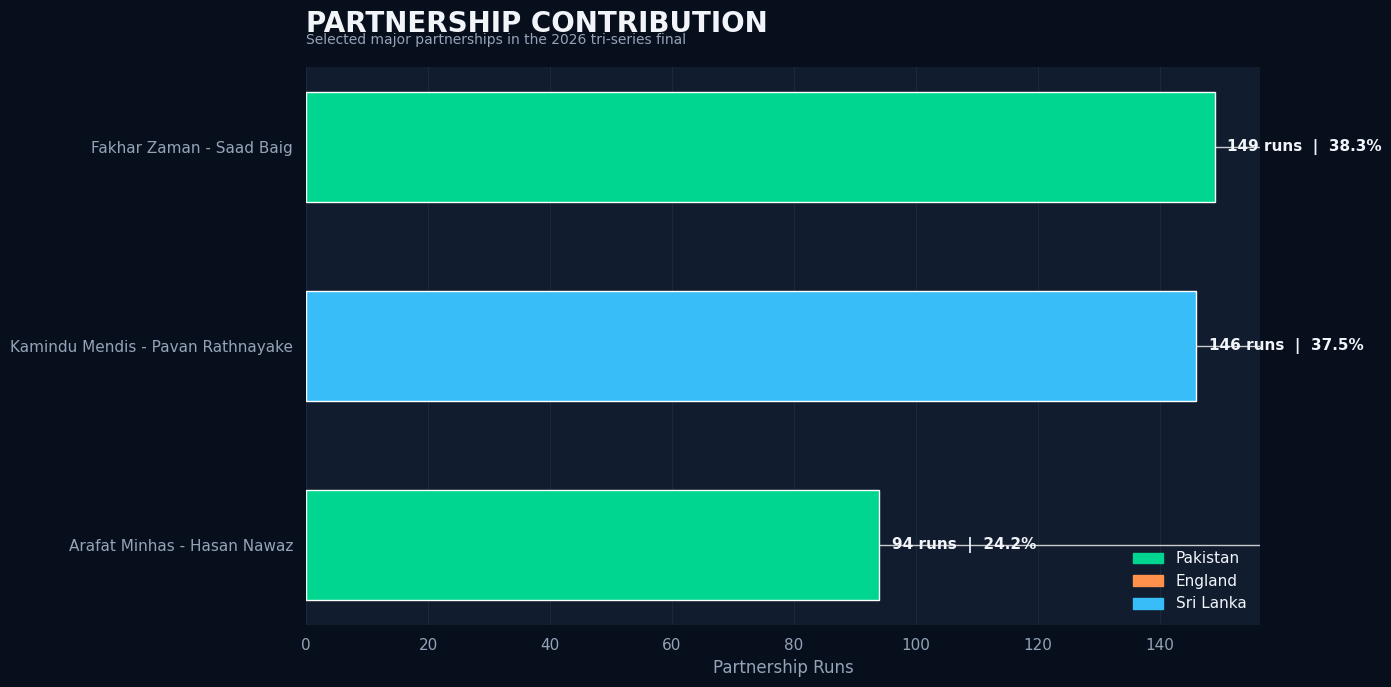

In [27]:

# PARTNERSHIP CONTRIBUTION ANALYSIS

fig, ax = plt.subplots(figsize=(14, 7))

style_axis(ax)

plot_data = partnerships.sort_values("runs")

total_partnership_runs = plot_data["runs"].sum()

bars = ax.barh(
    plot_data["partnership"],
    plot_data["runs"],
    color=[
        COLORS[team]
        for team in plot_data["team"]
    ],
    height=0.55
)

for bar, (_, row) in zip(bars, plot_data.iterrows()):

    percentage = (
        row["runs"] /
        total_partnership_runs * 100
    )

    ax.text(
        bar.get_width() + 2,
        bar.get_y() + bar.get_height()/2,
        f'{row["runs"]} runs  |  {percentage:.1f}%',
        va="center",
        fontsize=11,
        color=WHITE,
        fontweight="bold"
    )

ax.set_title(
    "PARTNERSHIP CONTRIBUTION",
    loc="left",
    fontsize=20,
    pad=25
)

ax.text(
    0,
    1.04,
    "Selected major partnerships in the 2026 tri-series final",
    transform=ax.transAxes,
    color=MUTED,
    fontsize=10
)

ax.set_xlabel("Partnership Runs")

ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=COLORS[team])
        for team in COLORS
    ],
    labels=list(COLORS.keys()),
    frameon=False,
    labelcolor=WHITE
)

plt.tight_layout()

plt.savefig(
    "professional_visuals/05_partnership_contribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [28]:

# VERIFIED FINAL MATCH BATTING DATA

final_batting = pd.DataFrame({
    "player": [
        "Fakhar Zaman",
        "Saad Baig",
        "Hasan Nawaz",
        "Arafat Minhas",
        "Kamindu Mendis",
        "Pavan Rathnayake"
    ],

    "team": [
        "Pakistan",
        "Pakistan",
        "Pakistan",
        "Pakistan",
        "Sri Lanka",
        "Sri Lanka"
    ],

    "runs": [127, 74, 37, 61, 131, 77],

    "balls": [99, 75, 45, 31, 128, 65]
})

final_batting["strike_rate"] = (
    final_batting["runs"] /
    final_batting["balls"] * 100
)

display(final_batting.round(2))


# VERIFIED MAJOR PARTNERSHIPS

partnerships = pd.DataFrame({
    "partnership": [
        "Fakhar Zaman - Saad Baig",
        "Hasan Nawaz - Arafat Minhas"
    ],

    "team": [
        "Pakistan",
        "Pakistan"
    ],

    "runs": [149, 94]
})

display(partnerships)


,player,team,runs,balls,strike_rate
0,Fakhar Zaman,Pakistan,127,99,128.28
1,Saad Baig,Pakistan,74,75,98.67
2,Hasan Nawaz,Pakistan,37,45,82.22
3,Arafat Minhas,Pakistan,61,31,196.77
4,Kamindu Mendis,Sri Lanka,131,128,102.34
5,Pavan Rathnayake,Sri Lanka,77,65,118.46


,partnership,team,runs
0,Fakhar Zaman - Saad Baig,Pakistan,149
1,Hasan Nawaz - Arafat Minhas,Pakistan,94


In [29]:

import zipfile
import os

visual_files = [
    "01_team_performance_dashboard.png",
    "02_high_low_scoring.png",
    "03_match_scoring_profile.png",
    "04_batting_performance_matrix.png",
    "05_partnership_contribution.png"
]

with zipfile.ZipFile(
    "Pakistan_Tri_Series_Professional_Visuals.zip",
    "w"
) as archive:

    for filename in visual_files:

        path = os.path.join(
            "professional_visuals",
            filename
        )

        if os.path.exists(path):
            archive.write(path)

print("Professional visualisation package created.")

from google.colab import files

files.download(
    "Pakistan_Tri_Series_Professional_Visuals.zip"
)


Professional visualisation package created.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

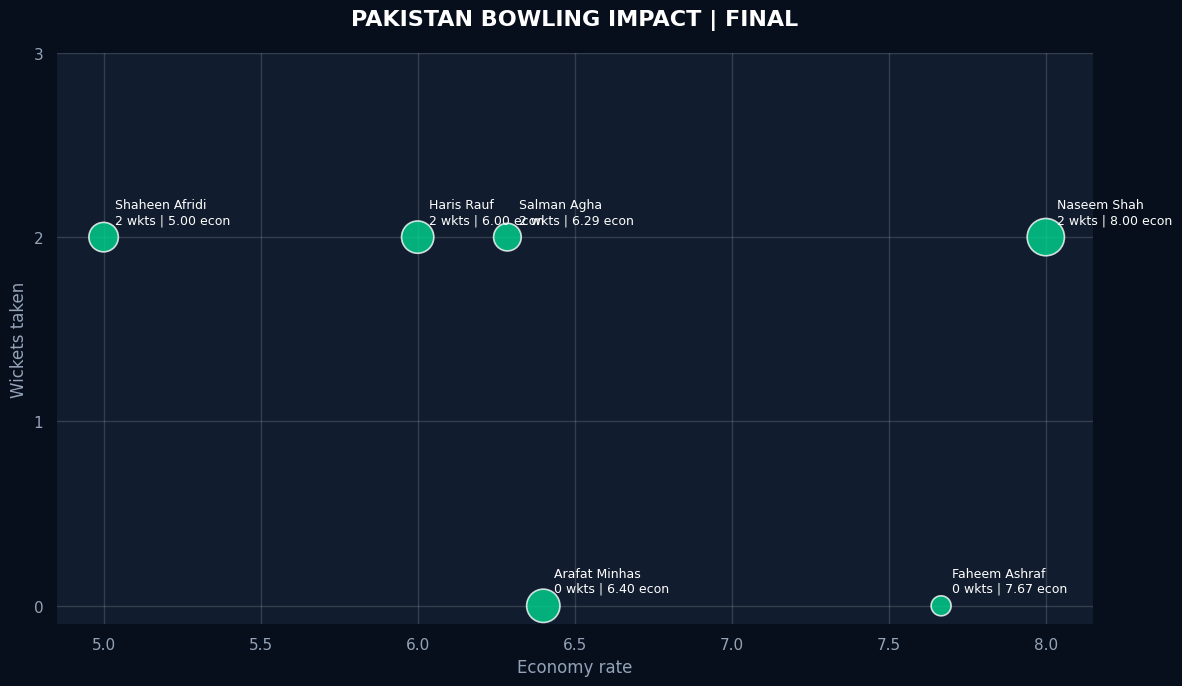

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

bowling = pd.DataFrame({
    "bowler": [
        "Shaheen Afridi", "Naseem Shah", "Arafat Minhas",
        "Salman Agha", "Haris Rauf", "Faheem Ashraf"
    ],
    "overs": [10, 10, 10, 7, 10, 3],
    "runs": [50, 80, 64, 44, 60, 23],
    "wickets": [2, 2, 0, 2, 2, 0]
})

bowling["economy"] = bowling["runs"] / bowling["overs"]

fig, ax = plt.subplots(figsize=(12, 7))

fig.patch.set_facecolor("#080F1C")
ax.set_facecolor("#111C2E")

sizes = bowling["runs"] * 9

ax.scatter(
    bowling["economy"],
    bowling["wickets"],
    s=sizes,
    color="#00D68F",
    alpha=0.8,
    edgecolors="white",
    linewidth=1.2
)

for _, r in bowling.iterrows():
    ax.annotate(
        f'{r["bowler"]}\n{int(r["wickets"])} wkts | {r["economy"]:.2f} econ',
        (r["economy"], r["wickets"]),
        xytext=(8, 10),
        textcoords="offset points",
        color="white",
        fontsize=9
    )

ax.set_title(
    "PAKISTAN BOWLING IMPACT | FINAL",
    color="white", fontsize=16, fontweight="bold", pad=20
)
ax.set_xlabel("Economy rate", color="#94A3B8")
ax.set_ylabel("Wickets taken", color="#94A3B8")
ax.set_yticks([0, 1, 2, 3])
ax.grid(alpha=0.15, color="white")

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(colors="#94A3B8")
plt.tight_layout()
plt.savefig("professional_visuals/bowling_impact_map.png",
            dpi=300, bbox_inches="tight")
plt.show()

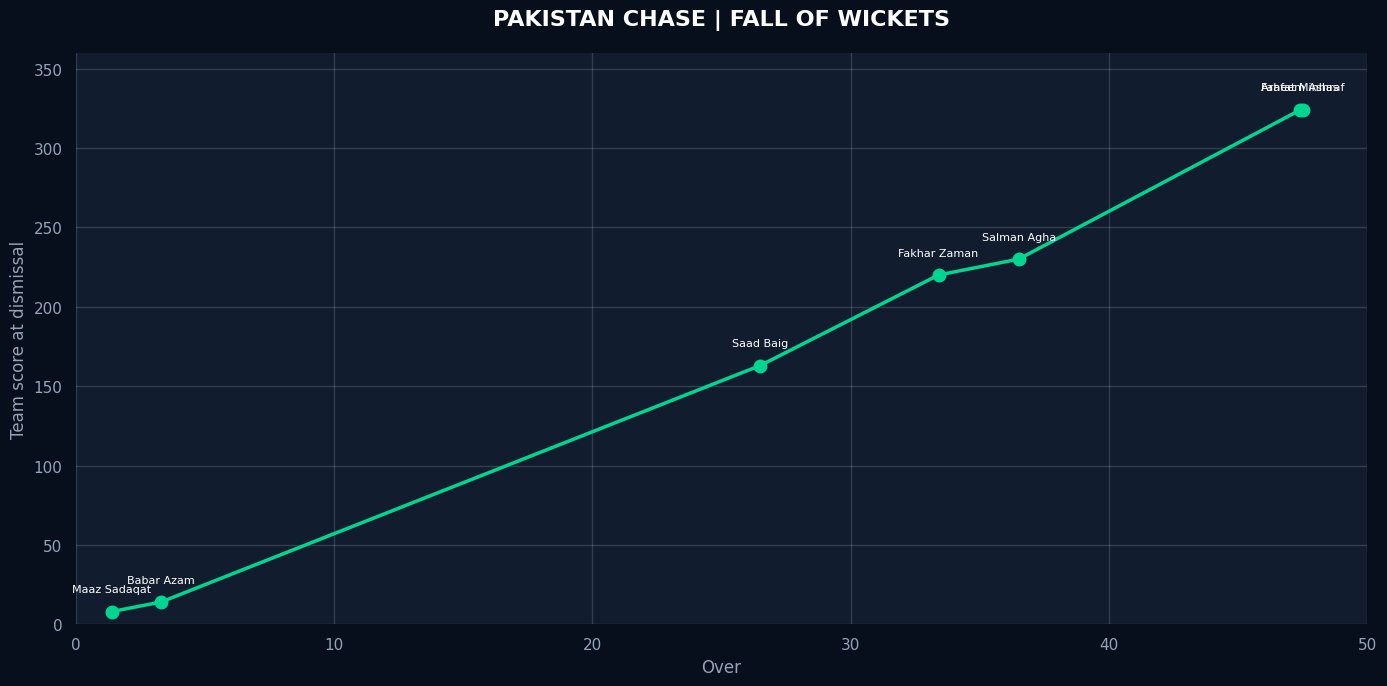

In [31]:
import matplotlib.pyplot as plt

wickets = [
    {"player": "Maaz Sadaqat", "runs": 8, "over": 1.4},
    {"player": "Babar Azam", "runs": 14, "over": 3.3},
    {"player": "Saad Baig", "runs": 163, "over": 26.5},
    {"player": "Fakhar Zaman", "runs": 220, "over": 33.4},
    {"player": "Salman Agha", "runs": 230, "over": 36.5},
    {"player": "Arafat Minhas", "runs": 324, "over": 47.4},
    {"player": "Faheem Ashraf", "runs": 324, "over": 47.5}
]

fig, ax = plt.subplots(figsize=(14, 7))
fig.patch.set_facecolor("#080F1C")
ax.set_facecolor("#111C2E")

overs = [x["over"] for x in wickets]
scores = [x["runs"] for x in wickets]

ax.plot(
    overs, scores,
    color="#00D68F", linewidth=2.5,
    marker="o", markersize=9
)

for item in wickets:
    ax.annotate(
        item["player"],
        (item["over"], item["runs"]),
        xytext=(0, 14),
        textcoords="offset points",
        ha="center",
        color="white",
        fontsize=8
    )

ax.set_title(
    "PAKISTAN CHASE | FALL OF WICKETS",
    color="white", fontsize=16, fontweight="bold", pad=20
)
ax.set_xlabel("Over", color="#94A3B8")
ax.set_ylabel("Team score at dismissal", color="#94A3B8")
ax.set_xlim(0, 50)
ax.set_ylim(0, 360)
ax.grid(alpha=0.15, color="white")

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(colors="#94A3B8")
plt.tight_layout()
plt.savefig("professional_visuals/fall_of_wickets.png",
            dpi=300, bbox_inches="tight")
plt.show()

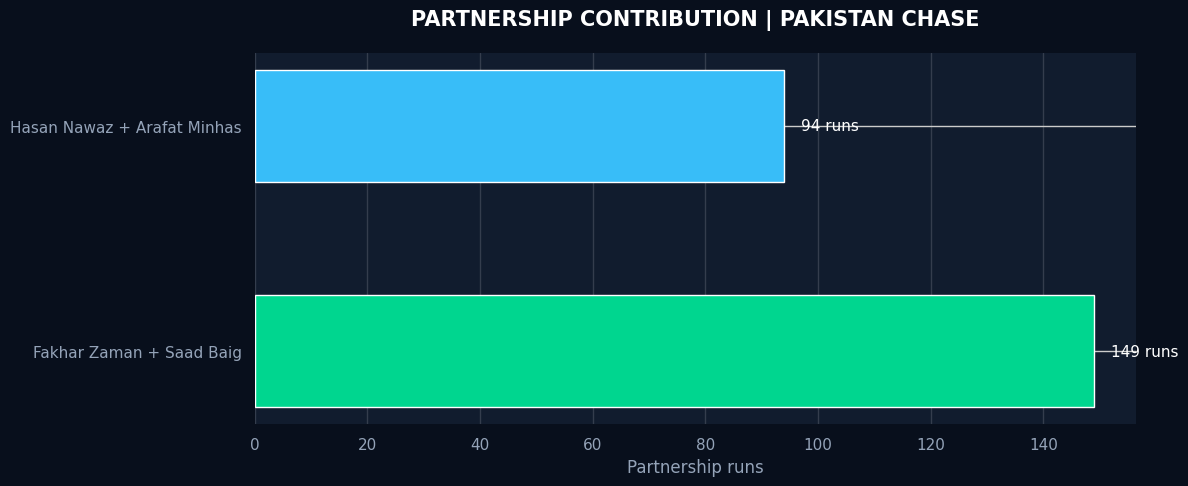

In [32]:
import matplotlib.pyplot as plt

partnerships_final = pd.DataFrame({
    "partnership": [
        "Fakhar Zaman + Saad Baig",
        "Hasan Nawaz + Arafat Minhas"
    ],
    "runs": [149, 94]
})

fig, ax = plt.subplots(figsize=(12, 5))
fig.patch.set_facecolor("#080F1C")
ax.set_facecolor("#111C2E")

bars = ax.barh(
    partnerships_final["partnership"],
    partnerships_final["runs"],
    color=["#00D68F", "#38BDF8"],
    height=0.5
)

for bar in bars:
    ax.text(
        bar.get_width() + 3,
        bar.get_y() + bar.get_height()/2,
        f'{int(bar.get_width())} runs',
        va="center", color="white", fontsize=11
    )

ax.set_title(
    "PARTNERSHIP CONTRIBUTION | PAKISTAN CHASE",
    color="white", fontsize=15, fontweight="bold", pad=20
)
ax.set_xlabel("Partnership runs", color="#94A3B8")
ax.grid(axis="x", alpha=0.15, color="white")
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.tick_params(colors="#94A3B8")
plt.tight_layout()
plt.savefig("professional_visuals/partnership_contribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [33]:
import requests

url = "https://cricsheet.org/downloads/"

response = requests.get(url)

print(response.status_code)
print(response.text[:1000])

200
<!DOCTYPE html>



 <html lang="en-gb" class="no-js"> 
<head>
  <meta http-equiv="content-type" content="text/html; charset=utf-8">
<meta name="mobile-web-app-capable" content="yes" />
<meta name="viewport" content="width=device-width, initial-scale=1.0">
<meta http-equiv="X-UA-Compatible" content="IE=edge,chrome=1">
<link rel="stylesheet" href="/css/main.css">
<link rel="alternate" type="application/rss+xml" href='http://cricsheet.org/articles.xml' />

<script src="/js/modernizr-3.6.0.min.js"></script>
<script type="text/javascript" src="//use.typekit.net/mjy1jks.js"></script>
<script type="text/javascript">try{Typekit.load();}catch(e){}</script>
<title>Available match data downloads - Cricsheet</title>

</head>

<body>
  <div class="wrapper wrapper_banner">
  <div id="banner">
    <header>
      <h1><a href="/">Cricsheet</a></h1>
      <h2>Freely-available structured data for cricket, including ball-by-ball data international and T20 League cricket matches, and identifier (regist

In [34]:
from bs4 import BeautifulSoup

soup = BeautifulSoup(response.text, "html.parser")

for link in soup.find_all("a", href=True):
    href = link["href"]
    if href.endswith(".zip"):
        print(link.get_text(" ", strip=True), "→", href)

JSON → /downloads/recently_added_2_json.zip
YAML → /downloads/recently_added_2.zip
JSON → /downloads/recently_added_2_female_json.zip
YAML → /downloads/recently_added_2_female.zip
JSON → /downloads/recently_added_2_male_json.zip
YAML → /downloads/recently_added_2_male.zip
JSON → /downloads/recently_added_7_json.zip
YAML → /downloads/recently_added_7.zip
JSON → /downloads/recently_added_7_female_json.zip
YAML → /downloads/recently_added_7_female.zip
JSON → /downloads/recently_added_7_male_json.zip
YAML → /downloads/recently_added_7_male.zip
JSON → /downloads/recently_added_30_json.zip
YAML → /downloads/recently_added_30.zip
JSON → /downloads/recently_added_30_female_json.zip
YAML → /downloads/recently_added_30_female.zip
JSON → /downloads/recently_added_30_male_json.zip
YAML → /downloads/recently_added_30_male.zip
JSON → /downloads/recently_played_2_json.zip
YAML → /downloads/recently_played_2.zip
JSON → /downloads/recently_played_2_female_json.zip
YAML → /downloads/recently_played_2_fe

In [35]:
import requests
import zipfile
import os

url = "https://cricsheet.org/downloads/recently_played_30_male_json.zip"

zip_path = "/content/cricket_recent_matches.zip"

print("Downloading recent men's cricket data...")

response = requests.get(url, stream=True)
response.raise_for_status()

with open(zip_path, "wb") as f:
    for chunk in response.iter_content(chunk_size=1024 * 1024):
        if chunk:
            f.write(chunk)

print("Download complete!")

with zipfile.ZipFile(zip_path, "r") as z:
    files_in_zip = z.namelist()

print("Files inside archive:", len(files_in_zip))
print("\nFirst 10 filenames:")
for filename in files_in_zip[:10]:
    print(filename)

Download complete!
Files inside archive: 143

First 10 filenames:
README.txt
1529230.json
1554410.json
1554533.json
1554534.json
1554535.json
1554536.json
1554537.json
1554538.json
1555136.json


In [36]:
import zipfile
import json
from datetime import date

zip_path = "/content/cricket_recent_matches.zip"

target_teams = {"Pakistan", "England", "Sri Lanka"}

found_matches = []

with zipfile.ZipFile(zip_path, "r") as z:

    for filename in z.namelist():

        if not filename.endswith(".json"):
            continue

        with z.open(filename) as f:
            match = json.load(f)

        info = match.get("info", {})

        teams = set(info.get("teams", []))
        dates = info.get("dates", [])

        if not dates:
            continue

        match_date = str(dates[0])

        if not ("2026-10-18" <= match_date <= "2026-10-31"):
            continue

        if teams.issubset(target_teams) and len(teams) == 2:

            found_matches.append({
                "file": filename,
                "date": match_date,
                "teams": " vs ".join(info.get("teams", [])),
                "venue": info.get("venue", "Unknown"),
                "event": info.get("event", {})
            })

print("MATCHES FOUND:", len(found_matches))

for match in sorted(found_matches, key=lambda x: x["date"]):
    print("\nDate:", match["date"])
    print("Teams:", match["teams"])
    print("Venue:", match["venue"])
    print("File:", match["file"])

MATCHES FOUND: 7

Date: 2026-10-18
Teams: Pakistan vs Sri Lanka
Venue: Rawalpindi Cricket Stadium
File: 1550713.json

Date: 2026-10-20
Teams: Pakistan vs England
Venue: Rawalpindi Cricket Stadium
File: 1550714.json

Date: 2026-10-22
Teams: England vs Sri Lanka
Venue: Rawalpindi Cricket Stadium
File: 1550715.json

Date: 2026-10-25
Teams: England vs Pakistan
Venue: Gaddafi Stadium, Lahore
File: 1550716.json

Date: 2026-10-27
Teams: Pakistan vs Sri Lanka
Venue: Gaddafi Stadium, Lahore
File: 1550717.json

Date: 2026-10-29
Teams: England vs Sri Lanka
Venue: Gaddafi Stadium, Lahore
File: 1550718.json

Date: 2026-10-31
Teams: Sri Lanka vs Pakistan
Venue: Gaddafi Stadium, Lahore
File: 1550719.json


In [37]:
import zipfile
import json
import pandas as pd
import os

zip_path = "/content/cricket_recent_matches.zip"

match_files = [
    "1550713.json",
    "1550714.json",
    "1550715.json",
    "1550716.json",
    "1550717.json",
    "1550718.json",
    "1550719.json"
]

delivery_records = []

with zipfile.ZipFile(zip_path, "r") as z:

    for filename in match_files:

        with z.open(filename) as f:
            match = json.load(f)

        info = match["info"]
        match_id = filename.replace(".json", "")

        teams = info["teams"]
        match_date = str(info["dates"][0])
        venue = info.get("venue", "Unknown")

        outcome = info.get("outcome", {})
        winner = outcome.get("winner", "Unknown")

        for innings_number, innings in enumerate(
            match["innings"], start=1
        ):

            batting_team = innings["team"]

            bowling_team = next(
                (team for team in teams if team != batting_team),
                "Unknown"
            )

            for over_data in innings["overs"]:

                over_number = over_data["over"] + 1

                for ball_number, delivery in enumerate(
                    over_data["deliveries"], start=1
                ):

                    runs = delivery.get("runs", {})
                    extras = delivery.get("extras", {})
                    wickets = delivery.get("wickets", [])

                    wicket_names = [
                        w.get("player_out", "")
                        for w in wickets
                    ]

                    wicket_types = [
                        w.get("kind", "")
                        for w in wickets
                    ]

                    is_legal = not (
                        "wides" in extras or
                        "noballs" in extras
                    )

                    delivery_records.append({

                        "match_id": match_id,
                        "date": match_date,
                        "venue": venue,
                        "winner": winner,

                        "innings": innings_number,
                        "batting_team": batting_team,
                        "bowling_team": bowling_team,

                        "over": over_number,
                        "ball_in_over": ball_number,

                        "batter": delivery["batter"],
                        "bowler": delivery["bowler"],
                        "non_striker": delivery["non_striker"],

                        "batter_runs": runs.get("batter", 0),
                        "extras": runs.get("extras", 0),
                        "total_runs": runs.get("total", 0),

                        "wicket": len(wickets),
                        "player_out": ", ".join(wicket_names),
                        "wicket_type": ", ".join(wicket_types),

                        "legal_ball": int(is_legal),
                        "extra_types": ", ".join(extras.keys())
                    })


# Create the complete delivery dataset
deliveries = pd.DataFrame(delivery_records)

# Create a folder for our project outputs
os.makedirs("tri_series_data", exist_ok=True)

# Save the complete dataset
deliveries.to_csv(
    "tri_series_data/tri_series_deliveries.csv",
    index=False
)

# Display basic information
print("DATASET CREATED SUCCESSFULLY")
print("--------------------------------")
print("Total deliveries:", len(deliveries))
print("Matches:", deliveries["match_id"].nunique())
print("Teams:", deliveries["batting_team"].nunique())
print("Innings:", deliveries[["match_id", "innings"]].drop_duplicates().shape[0])

print("\nDATASET DIMENSIONS:")
print(deliveries.shape)

print("\nFIRST 10 ROWS:")
display(deliveries.head(10))

print("\nMATCH-WISE INNINGS TOTALS:")

match_totals = (
    deliveries.groupby(
        ["date", "match_id", "innings", "batting_team", "bowling_team"]
    )
    .agg(
        total_runs=("total_runs", "sum"),
        wickets=("wicket", "sum"),
        legal_balls=("legal_ball", "sum")
    )
    .reset_index()
)

display(match_totals)

print("\nFILES SAVED:")
print("tri_series_data/tri_series_deliveries.csv")

DATASET CREATED SUCCESSFULLY
--------------------------------
Total deliveries: 3793
Matches: 7
Teams: 3
Innings: 14

DATASET DIMENSIONS:
(3793, 20)

FIRST 10 ROWS:


,match_id,date,venue,winner,innings,batting_team,bowling_team,over,ball_in_over,batter,bowler,non_striker,batter_runs,extras,total_runs,wicket,player_out,wicket_type,legal_ball,extra_types
0,1550713,2026-10-18,Rawalpindi Cricket Stadium,Pakistan,1,Pakistan,Sri Lanka,1,1,Fakhar Zaman,AM Fernando,Saim Ayub,0,0,0,0,,,1,
1,1550713,2026-10-18,Rawalpindi Cricket Stadium,Pakistan,1,Pakistan,Sri Lanka,1,2,Fakhar Zaman,AM Fernando,Saim Ayub,0,0,0,0,,,1,
2,1550713,2026-10-18,Rawalpindi Cricket Stadium,Pakistan,1,Pakistan,Sri Lanka,1,3,Fakhar Zaman,AM Fernando,Saim Ayub,0,0,0,0,,,1,
3,1550713,2026-10-18,Rawalpindi Cricket Stadium,Pakistan,1,Pakistan,Sri Lanka,1,4,Fakhar Zaman,AM Fernando,Saim Ayub,0,0,0,0,,,1,
4,1550713,2026-10-18,Rawalpindi Cricket Stadium,Pakistan,1,Pakistan,Sri Lanka,1,5,Fakhar Zaman,AM Fernando,Saim Ayub,0,0,0,0,,,1,
5,1550713,2026-10-18,Rawalpindi Cricket Stadium,Pakistan,1,Pakistan,Sri Lanka,1,6,Fakhar Zaman,AM Fernando,Saim Ayub,0,0,0,0,,,1,
6,1550713,2026-10-18,Rawalpindi Cricket Stadium,Pakistan,1,Pakistan,Sri Lanka,2,1,Saim Ayub,D Madushanka,Fakhar Zaman,1,0,1,0,,,1,
7,1550713,2026-10-18,Rawalpindi Cricket Stadium,Pakistan,1,Pakistan,Sri Lanka,2,2,Fakhar Zaman,D Madushanka,Saim Ayub,0,1,1,0,,,0,noballs
8,1550713,2026-10-18,Rawalpindi Cricket Stadium,Pakistan,1,Pakistan,Sri Lanka,2,3,Fakhar Zaman,D Madushanka,Saim Ayub,6,0,6,0,,,1,
9,1550713,2026-10-18,Rawalpindi Cricket Stadium,Pakistan,1,Pakistan,Sri Lanka,2,4,Fakhar Zaman,D Madushanka,Saim Ayub,1,0,1,0,,,1,



MATCH-WISE INNINGS TOTALS:


,date,match_id,innings,batting_team,bowling_team,total_runs,wickets,legal_balls
0,2026-10-18,1550713,1,Pakistan,Sri Lanka,305,10,299
1,2026-10-18,1550713,2,Sri Lanka,Pakistan,268,10,289
2,2026-10-20,1550714,1,Pakistan,England,302,9,300
3,2026-10-20,1550714,2,England,Pakistan,215,10,232
4,2026-10-22,1550715,1,England,Sri Lanka,429,4,300
5,2026-10-22,1550715,2,Sri Lanka,England,430,8,299
6,2026-10-25,1550716,1,England,Pakistan,241,10,280
7,2026-10-25,1550716,2,Pakistan,England,243,9,283
8,2026-10-27,1550717,1,Pakistan,Sri Lanka,110,10,153
9,2026-10-27,1550717,2,Sri Lanka,Pakistan,114,2,109



FILES SAVED:
tri_series_data/tri_series_deliveries.csv


In [38]:
# Aggregate deliveries into overs

over_summary = (
    deliveries.groupby(
        ["match_id", "date", "innings",
         "batting_team", "bowling_team", "over"]
    )
    .agg(
        runs=("total_runs", "sum"),
        wickets=("wicket", "sum"),
        legal_balls=("legal_ball", "sum")
    )
    .reset_index()
)

# Calculate cumulative innings performance

over_summary = over_summary.sort_values(
    ["match_id", "innings", "over"]
)

over_summary["cumulative_runs"] = (
    over_summary.groupby(
        ["match_id", "innings"]
    )["runs"].cumsum()
)

over_summary["cumulative_wickets"] = (
    over_summary.groupby(
        ["match_id", "innings"]
    )["wickets"].cumsum()
)

over_summary["cumulative_balls"] = (
    over_summary.groupby(
        ["match_id", "innings"]
    )["legal_balls"].cumsum()
)

over_summary["run_rate"] = (
    over_summary["cumulative_runs"] /
    over_summary["cumulative_balls"] * 6
)

over_summary.to_csv(
    "tri_series_data/tri_series_over_summary.csv",
    index=False
)

print("OVER-BY-OVER DATA CREATED")
print("Total over records:", len(over_summary))

display(over_summary.head(15))

OVER-BY-OVER DATA CREATED
Total over records: 623


,match_id,date,innings,batting_team,bowling_team,over,runs,wickets,legal_balls,cumulative_runs,cumulative_wickets,cumulative_balls,run_rate
0,1550713,2026-10-18,1,Pakistan,Sri Lanka,1,0,0,6,0,0,6,0.000000
1,1550713,2026-10-18,1,Pakistan,Sri Lanka,2,9,0,6,9,0,12,4.500000
2,1550713,2026-10-18,1,Pakistan,Sri Lanka,3,8,0,6,17,0,18,5.666667
3,1550713,2026-10-18,1,Pakistan,Sri Lanka,4,6,1,6,23,1,24,5.750000
4,1550713,2026-10-18,1,Pakistan,Sri Lanka,5,8,0,6,31,1,30,6.200000
5,1550713,2026-10-18,1,Pakistan,Sri Lanka,6,1,1,6,32,2,36,5.333333
6,1550713,2026-10-18,1,Pakistan,Sri Lanka,7,7,0,6,39,2,42,5.571429
7,1550713,2026-10-18,1,Pakistan,Sri Lanka,8,8,0,6,47,2,48,5.875000
8,1550713,2026-10-18,1,Pakistan,Sri Lanka,9,3,0,6,50,2,54,5.555556
9,1550713,2026-10-18,1,Pakistan,Sri Lanka,10,4,0,6,54,2,60,5.400000


In [39]:
# Tournament data validation

actual_totals = (
    deliveries.groupby(
        ["date", "batting_team", "innings"]
    )
    .agg(
        runs=("total_runs", "sum"),
        wickets=("wicket", "sum"),
        legal_balls=("legal_ball", "sum")
    )
    .reset_index()
    .sort_values(["date", "innings"])
)

expected_totals = pd.DataFrame([
    ["2026-10-18", "Pakistan", 305, 10],
    ["2026-10-18", "Sri Lanka", 268, 10],
    ["2026-10-20", "Pakistan", 302, 9],
    ["2026-10-20", "England", 215, 10],
    ["2026-10-22", "England", 429, 4],
    ["2026-10-22", "Sri Lanka", 430, 8],
    ["2026-10-25", "England", 241, 10],
    ["2026-10-25", "Pakistan", 243, 9],
    ["2026-10-27", "Pakistan", 110, 10],
    ["2026-10-27", "Sri Lanka", 114, 2],
    ["2026-10-29", "England", 386, 5],
    ["2026-10-29", "Sri Lanka", 331, 10],
    ["2026-10-31", "Sri Lanka", 325, 8],
    ["2026-10-31", "Pakistan", 331, 7]
], columns=["date", "batting_team", "expected_runs", "expected_wickets"])

validation = actual_totals.merge(
    expected_totals,
    on=["date", "batting_team"],
    how="outer",
    indicator=True
)

validation["runs_match"] = (
    validation["runs"] == validation["expected_runs"]
)

validation["wickets_match"] = (
    validation["wickets"] == validation["expected_wickets"]
)

print("TOURNAMENT SCORE VALIDATION")
display(validation)

if (
    validation["_merge"].eq("both").all()
    and validation["runs_match"].all()
    and validation["wickets_match"].all()
):
    print("SUCCESS: All 14 innings match the expected scorecard totals.")
else:
    print("CHECK REQUIRED: At least one innings needs investigation.")

TOURNAMENT SCORE VALIDATION


,date,batting_team,innings,runs,wickets,legal_balls,expected_runs,expected_wickets,_merge,runs_match,wickets_match
0,2026-10-18,Pakistan,1,305,10,299,305,10,both,True,True
1,2026-10-18,Sri Lanka,2,268,10,289,268,10,both,True,True
2,2026-10-20,England,2,215,10,232,215,10,both,True,True
3,2026-10-20,Pakistan,1,302,9,300,302,9,both,True,True
4,2026-10-22,England,1,429,4,300,429,4,both,True,True
5,2026-10-22,Sri Lanka,2,430,8,299,430,8,both,True,True
6,2026-10-25,England,1,241,10,280,241,10,both,True,True
7,2026-10-25,Pakistan,2,243,9,283,243,9,both,True,True
8,2026-10-27,Pakistan,1,110,10,153,110,10,both,True,True
9,2026-10-27,Sri Lanka,2,114,2,109,114,2,both,True,True


SUCCESS: All 14 innings match the expected scorecard totals.


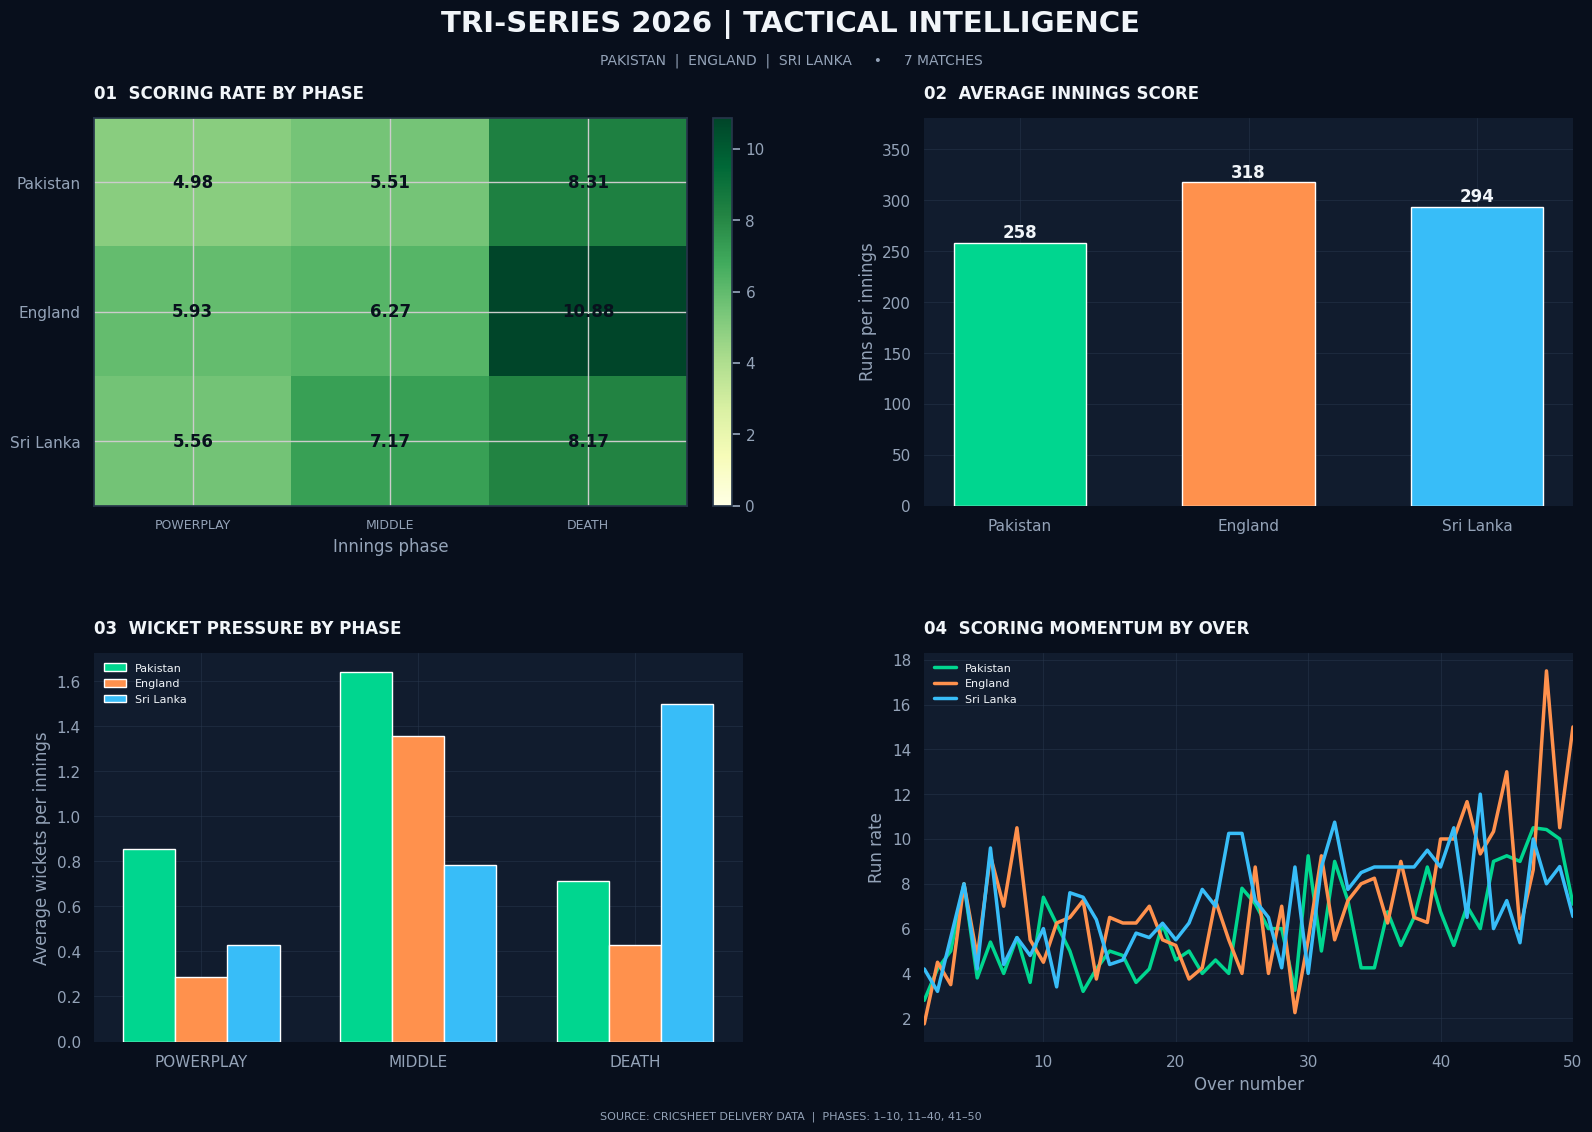

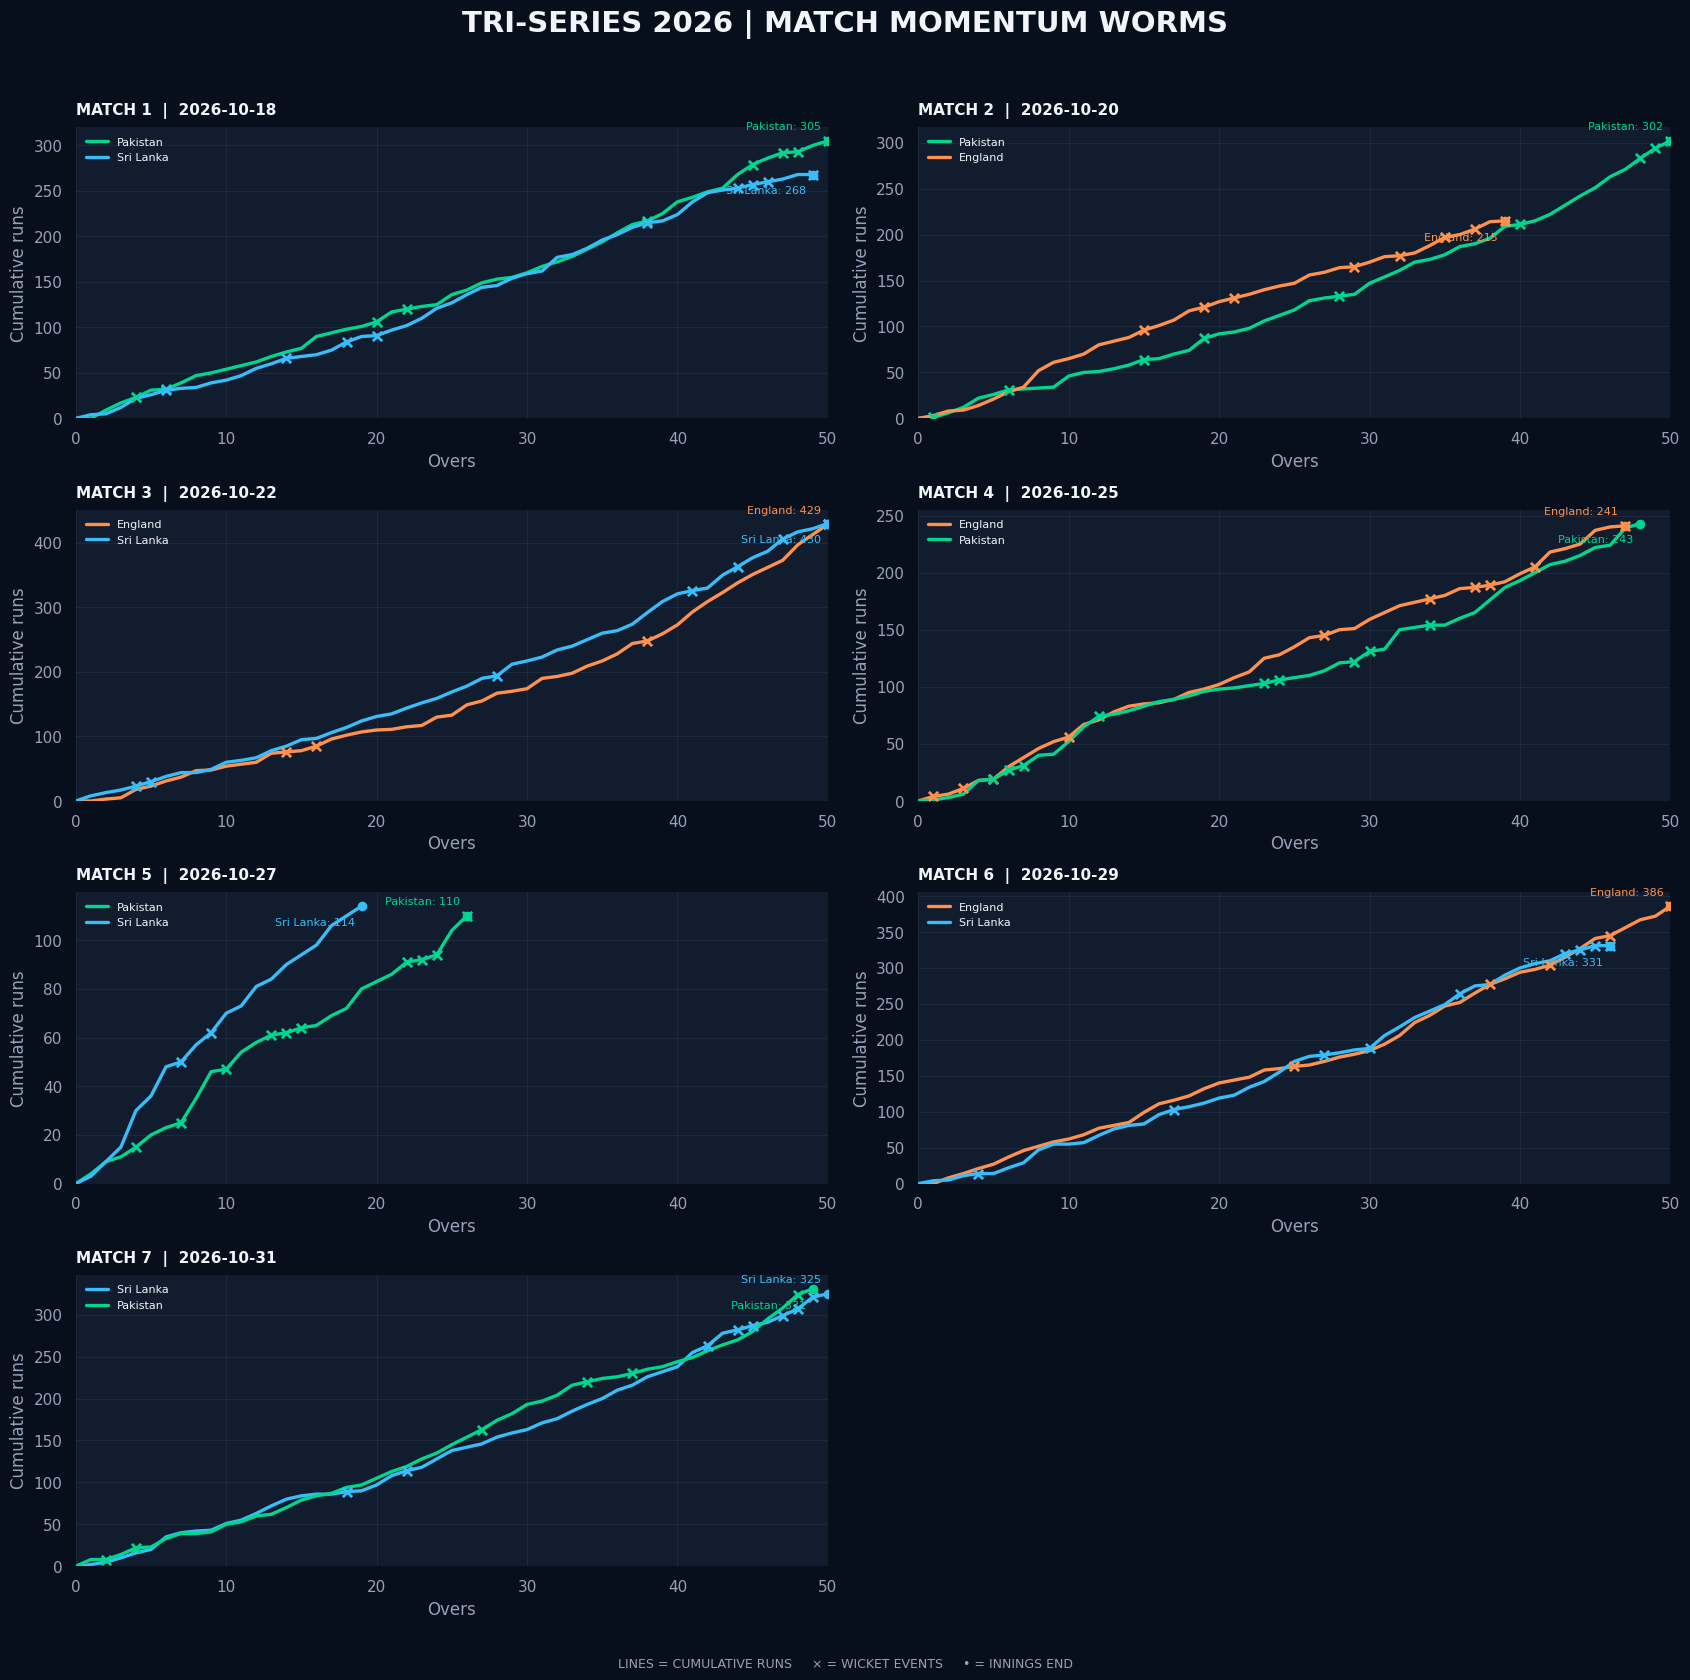

VISUALISATION PACKAGE COMPLETE
--------------------------------
1. Tournament Tactical Dashboard
2. Seven-Match Run-Rate Worm Collection

Saved inside: tri_series_visuals/


In [40]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import os

# ==========================================
# CRICKET TRI-SERIES | VISUAL ANALYTICS PACK
# ==========================================

os.makedirs("tri_series_visuals", exist_ok=True)

COLORS = {
    "Pakistan": "#00D68F",
    "England": "#FF914D",
    "Sri Lanka": "#38BDF8"
}

BG = "#080F1C"
PANEL = "#111C2E"
WHITE = "#F1F5F9"
MUTED = "#94A3B8"
GRID = "#29384D"

plt.rcParams.update({
    "figure.facecolor": BG,
    "axes.facecolor": PANEL,
    "savefig.facecolor": BG,
    "text.color": WHITE,
    "axes.labelcolor": MUTED,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titleweight": "bold"
})

def style_axis(ax):
    ax.set_facecolor(PANEL)
    ax.grid(color=GRID, alpha=0.5, linewidth=0.7)
    ax.set_axisbelow(True)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(colors=MUTED)

# ------------------------------------------
# PREPARE OVER DATA
# ------------------------------------------

ov = over_summary.copy()

ov["phase"] = pd.cut(
    ov["over"],
    bins=[0, 10, 40, 50],
    labels=["POWERPLAY", "MIDDLE", "DEATH"]
)

phase_order = ["POWERPLAY", "MIDDLE", "DEATH"]
teams = ["Pakistan", "England", "Sri Lanka"]

# ==========================================
# VISUAL 1: TOURNAMENT TACTICAL DASHBOARD
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(17, 12))
fig.subplots_adjust(
    left=0.09, right=0.96, top=0.87,
    bottom=0.10, hspace=0.38, wspace=0.28
)

fig.suptitle(
    "TRI-SERIES 2026 | TACTICAL INTELLIGENCE",
    fontsize=21, fontweight="bold", color=WHITE, y=0.96
)

fig.text(
    0.5, 0.915,
    "PAKISTAN  |  ENGLAND  |  SRI LANKA     •     7 MATCHES",
    ha="center", color=MUTED, fontsize=10
)

# PANEL A: PHASE RUN-RATE HEATMAP

ax = axes[0, 0]

phase_rr = (
    ov.groupby(["batting_team", "phase"], observed=False)
    .agg(
        runs=("runs", "sum"),
        balls=("legal_balls", "sum")
    )
    .reset_index()
)

phase_rr["run_rate"] = (
    phase_rr["runs"] / phase_rr["balls"] * 6
)

heat = phase_rr.pivot(
    index="batting_team",
    columns="phase",
    values="run_rate"
).reindex(index=teams, columns=phase_order)

im = ax.imshow(
    heat.values,
    cmap="YlGn",
    aspect="auto",
    vmin=0
)

ax.set_xticks(range(3))
ax.set_xticklabels(phase_order, fontsize=9)
ax.set_yticks(range(3))
ax.set_yticklabels(teams)

for i in range(3):
    for j in range(3):
        value = heat.iloc[i, j]
        if pd.notna(value):
            ax.text(
                j, i, f"{value:.2f}",
                ha="center", va="center",
                fontsize=12, fontweight="bold",
                color="#08111D"
            )

ax.set_title("01  SCORING RATE BY PHASE", loc="left", pad=14)
ax.set_xlabel("Innings phase")
ax.set_ylabel("")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# PANEL B: AVERAGE INNINGS SCORE

ax = axes[0, 1]

innings_totals = (
    deliveries.groupby(["match_id", "batting_team"])
    .agg(score=("total_runs", "sum"))
    .reset_index()
)

avg_score = (
    innings_totals.groupby("batting_team")["score"]
    .mean()
    .reindex(teams)
)

bars = ax.bar(
    teams,
    avg_score.values,
    color=[COLORS[t] for t in teams],
    width=0.58
)

for bar, value in zip(bars, avg_score.values):
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 5,
        f"{value:.0f}",
        ha="center", color=WHITE,
        fontsize=12, fontweight="bold"
    )

ax.set_title("02  AVERAGE INNINGS SCORE", loc="left", pad=14)
ax.set_ylabel("Runs per innings")
ax.set_ylim(0, max(avg_score.values) * 1.2)
style_axis(ax)

# PANEL C: WICKET PRESSURE BY PHASE

ax = axes[1, 0]

phase_wickets = (
    ov.groupby(["match_id", "innings", "batting_team", "phase"],
               observed=False)
    .agg(wickets=("wickets", "sum"))
    .reset_index()
)

phase_wickets_avg = (
    phase_wickets.groupby(["batting_team", "phase"],
                          observed=False)
    .agg(
        wickets=("wickets", "sum"),
        innings=("innings", "count")
    )
)

phase_wickets_avg["avg_wickets"] = (
    phase_wickets_avg["wickets"] /
    phase_wickets_avg["innings"]
)

x = np.arange(3)
width = 0.24

for i, team in enumerate(teams):
    values = [
        phase_wickets_avg.loc[(team, phase), "avg_wickets"]
        if (team, phase) in phase_wickets_avg.index else 0
        for phase in phase_order
    ]

    ax.bar(
        x + (i - 1) * width,
        values,
        width,
        label=team,
        color=COLORS[team]
    )

ax.set_xticks(x)
ax.set_xticklabels(phase_order)
ax.set_title("03  WICKET PRESSURE BY PHASE", loc="left", pad=14)
ax.set_ylabel("Average wickets per innings")
ax.legend(frameon=False, labelcolor=WHITE, fontsize=8)
style_axis(ax)

# PANEL D: OVER-BY-OVER SCORING PROFILE

ax = axes[1, 1]

for team in teams:
    team_over = (
        ov[ov["batting_team"] == team]
        .groupby("over")
        .agg(
            runs=("runs", "sum"),
            balls=("legal_balls", "sum")
        )
    )

    team_over["rate"] = (
        team_over["runs"] / team_over["balls"] * 6
    )

    ax.plot(
        team_over.index,
        team_over["rate"],
        color=COLORS[team],
        linewidth=2.5,
        label=team
    )

ax.set_title("04  SCORING MOMENTUM BY OVER", loc="left", pad=14)
ax.set_xlabel("Over number")
ax.set_ylabel("Run rate")
ax.set_xlim(1, 50)
ax.legend(frameon=False, labelcolor=WHITE, fontsize=8)
style_axis(ax)

fig.text(
    0.5, 0.035,
    "SOURCE: CRICSHEET DELIVERY DATA  |  PHASES: 1–10, 11–40, 41–50",
    ha="center", color=MUTED, fontsize=8
)

plt.savefig(
    "tri_series_visuals/01_tournament_tactical_dashboard.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


# ==========================================
# VISUAL 2: SEVEN-MATCH RUN-RATE WORMS
# ==========================================

match_ids = sorted(ov["match_id"].unique())

fig, axes = plt.subplots(4, 2, figsize=(17, 17))
axes = axes.flatten()

fig.suptitle(
    "TRI-SERIES 2026 | MATCH MOMENTUM WORMS",
    fontsize=21, fontweight="bold", color=WHITE, y=0.99
)

for idx, match_id in enumerate(match_ids):

    ax = axes[idx]

    match_data = ov[ov["match_id"] == match_id]

    innings_data = (
        match_data.groupby("innings")["batting_team"]
        .first()
        .to_dict()
    )

    for innings_num, team in innings_data.items():

        innings = (
            match_data[match_data["innings"] == innings_num]
            .sort_values("over")
        )

        x_values = [0] + innings["over"].tolist()
        y_values = [0] + innings["cumulative_runs"].tolist()

        ax.plot(
            x_values,
            y_values,
            color=COLORS[team],
            linewidth=2.4,
            label=team
        )

        # Mark overs containing wickets
        wicket_overs = innings[innings["wickets"] > 0]

        ax.scatter(
            wicket_overs["over"],
            wicket_overs["cumulative_runs"],
            color=COLORS[team],
            marker="x",
            s=45,
            linewidths=2,
            zorder=5
        )

        final = innings.iloc[-1]

        ax.scatter(
            final["over"],
            final["cumulative_runs"],
            color=COLORS[team],
            s=35,
            zorder=6
        )

        ax.annotate(
            f'{team}: {int(final["cumulative_runs"])}',
            (final["over"], final["cumulative_runs"]),
            xytext=(-5, 8 if innings_num == 1 else -14),
            textcoords="offset points",
            ha="right",
            fontsize=8,
            color=COLORS[team]
        )

    date = match_data["date"].iloc[0]

    ax.set_title(
        f"MATCH {idx+1}  |  {date}",
        loc="left", color=WHITE, fontsize=11, pad=9
    )

    ax.set_xlim(0, 50)
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Overs")
    ax.set_ylabel("Cumulative runs")
    style_axis(ax)

    ax.legend(
        frameon=False,
        labelcolor=WHITE,
        fontsize=8,
        loc="upper left"
    )

# Remove unused eighth panel
axes[7].axis("off")

fig.text(
    0.5, 0.015,
    "LINES = CUMULATIVE RUNS     × = WICKET EVENTS     • = INNINGS END",
    ha="center", color=MUTED, fontsize=9
)

plt.tight_layout(rect=[0, 0.035, 1, 0.97])

plt.savefig(
    "tri_series_visuals/02_seven_match_run_rate_worms.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


# ==========================================
# EXPORT BOTH VISUALS
# ==========================================

print("VISUALISATION PACKAGE COMPLETE")
print("--------------------------------")
print("1. Tournament Tactical Dashboard")
print("2. Seven-Match Run-Rate Worm Collection")
print("\nSaved inside: tri_series_visuals/")


In [41]:
import os
import shutil

os.makedirs("visuals", exist_ok=True)

shutil.copy(
    "tri_series_visuals/01_tournament_tactical_dashboard.png",
    "visuals/tactical_dashboard.png"
)

shutil.copy(
    "tri_series_visuals/02_seven_match_run_rate_worms.png",
    "visuals/seven_match_worms.png"
)

print("Visuals ready for GitHub!")

Visuals ready for GitHub!


In [42]:
from google.colab import files

files.download("visuals/tactical_dashboard.png")
files.download("visuals/seven_match_worms.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [50]:
files.download("tri_series_analysis.ipynb")

FileNotFoundError: Cannot find file: tri_series_analysis.ipynb

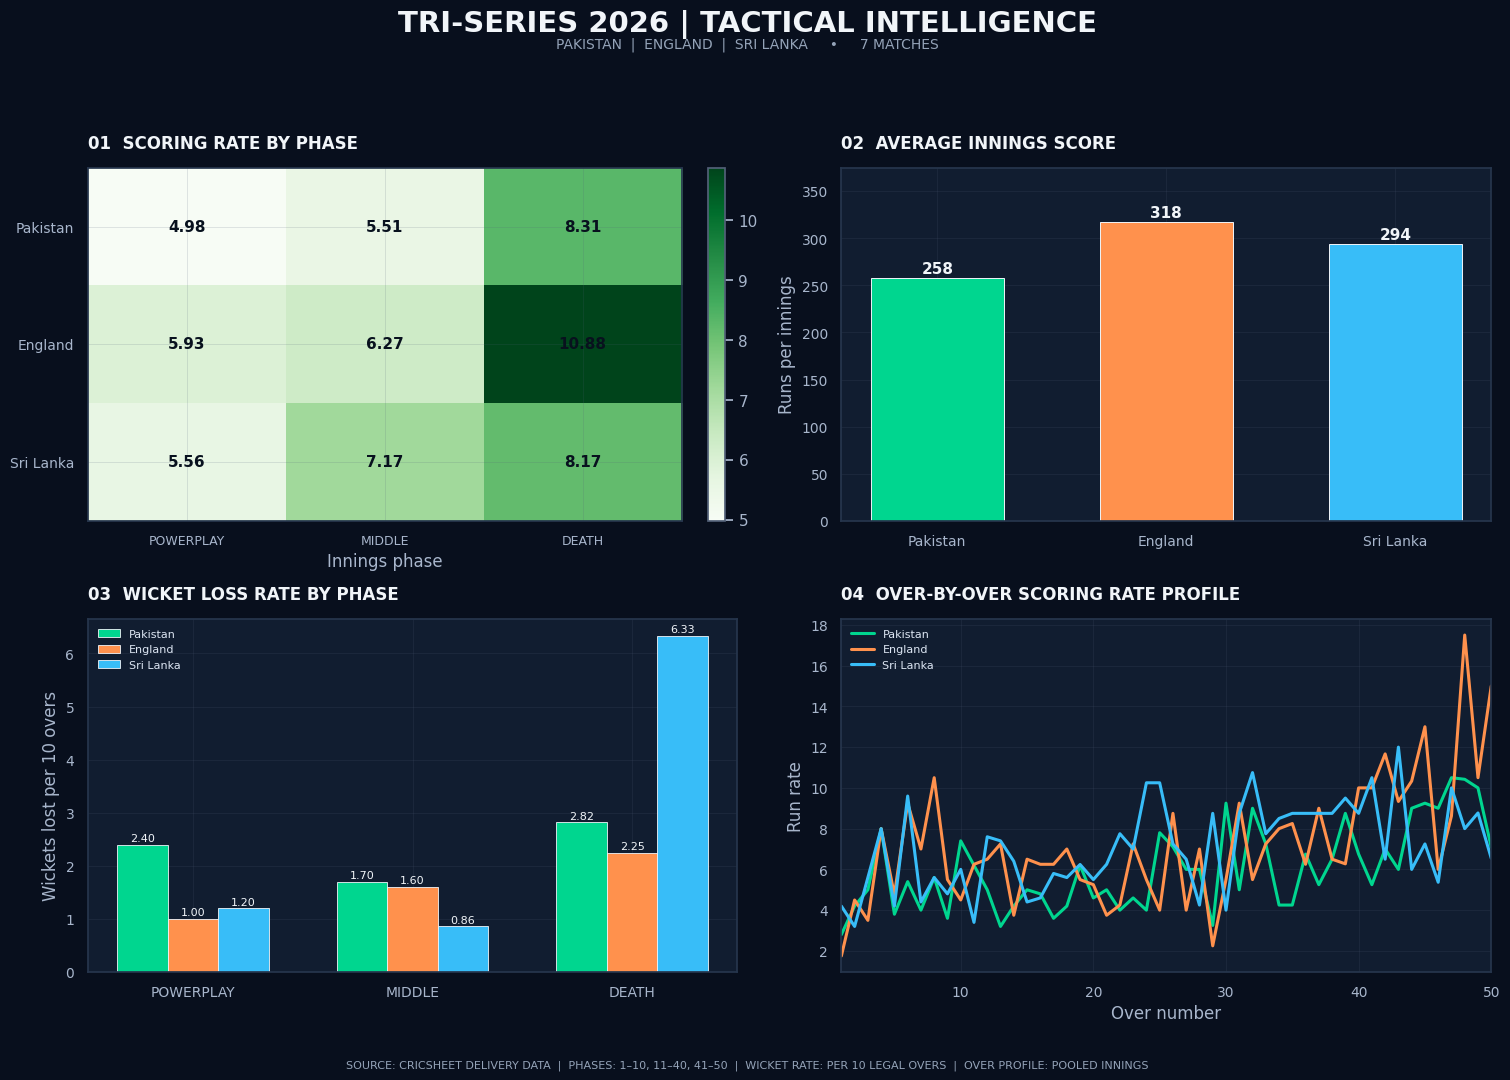

CORRECTED DASHBOARD SAVED SUCCESSFULLY


In [47]:

import os
import shutil
import zipfile

# Create the GitHub project folder
project = "tri-series-2026-cricket-tactical-analysis"
os.makedirs(f"{project}/visuals", exist_ok=True)
os.makedirs(f"{project}/data", exist_ok=True)

# Copy your finished visualisations
shutil.copy(
    "tri_series_visuals/01_tournament_tactical_dashboard.png",
    f"{project}/visuals/tactical_dashboard.png"
)

shutil.copy(
    "tri_series_visuals/02_seven_match_run_rate_worms.png",
    f"{project}/visuals/seven_match_worms.png"
)

# Create README
readme = """# Tri-Series 2026: Tactical Cricket Analytics

## Project Overview

This project examines the 2026 Pakistan–England–Sri Lanka ODI Tri-Series using ball-by-ball cricket data. It uses Python to explore scoring patterns, innings phases, wicket-loss rates and scoring profiles across seven matches.

The aim is to move beyond match results and examine how teams scored and lost wickets across different stages of an ODI innings.

## Tournament Coverage

- Teams: Pakistan, England and Sri Lanka
- Matches: Seven ODIs
- Dates: 18–31 October 2026
- Venues: Rawalpindi Cricket Stadium and Gaddafi Stadium, Lahore

## Research Questions

1. How did the teams' scoring rates differ across the Powerplay, middle and death overs?
2. Which team recorded the highest average innings score?
3. How did wicket-loss rates vary across innings phases?
4. How did scoring rates change across over numbers?

## Data and Tools

Ball-by-ball delivery data was obtained from Cricsheet.

Tools:
- Python
- Pandas
- NumPy
- Matplotlib
- Google Colab

PCB match records can be used as an official reference for tournament results.

## Analytical Approach

### 1. Tournament Tactical Dashboard

The dashboard brings together four comparisons:

- Scoring rate by innings phase
- Average innings score by team
- Wickets lost per 10 legal overs by phase
- Pooled over-by-over scoring rate profile

### 2. Seven-Match Run-Rate Worms

The second visualisation compares cumulative runs across the two innings of each match. It also marks wickets at over level to help identify changes in innings progression.

## Definitions

- Powerplay: Overs 1–10
- Middle overs: Overs 11–40
- Death overs: Overs 41–50
- Run rate: Runs divided by legal balls, multiplied by six
- Wicket-loss rate: Wickets lost per 10 legal overs

## Visualisations

### Tournament Tactical Dashboard

![Tournament Tactical Dashboard](visuals/tactical_dashboard.png)

### Seven-Match Run-Rate Worms

![Seven-Match Run-Rate Worms](visuals/seven_match_worms.png)

## Limitations

The over-by-over scoring profile pools deliveries across available innings. Later overs may contain fewer observations because some innings finish before the 50th over.

Wicket-loss rates are normalized by legal balls faced. They should still be interpreted in light of differences in innings length and the number of observations.

The available delivery data does not contain shot coordinates. Therefore, this project does not claim to produce pitch maps or wagon-wheel visualisations.

## Further Development

Future work could examine partnerships, batter and bowler performance, boundary contribution, and match-specific turning points.

## Author

Qurat Ul Ain Ali
"""

with open(f"{project}/README.md", "w", encoding="utf-8") as f:
    f.write(readme)

# Create requirements file
with open(f"{project}/requirements.txt", "w") as f:
    f.write("pandas\nnumpy\nmatplotlib\n")

# Explain the data source without uploading the full archive
data_readme = """# Data

This project uses ball-by-ball delivery data from Cricsheet.

Download the relevant men's JSON data from:
https://cricsheet.org/downloads/

The analysis uses the seven 2026 Pakistan–England–Sri Lanka Tri-Series matches dated 18–31 October 2026.

The full Cricsheet archive is not included in this repository. The notebook contains the extraction and preparation workflow.

Official tournament results can be cross-checked against the Pakistan Cricket Board:
https://www.pcb.com.pk/
"""

with open(f"{project}/data/README.md", "w", encoding="utf-8") as f:
    f.write(data_readme)

# Create a ZIP of the prepared GitHub files
zip_name = f"{project}_github_files.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for root, dirs, files in os.walk(project):
        for file in files:
            path = os.path.join(root, file)
            z.write(path, path)

print("PROJECT FILES PREPARED")
print("ZIP:", zip_name)

from google.colab import files
files.download(zip_name)


PROJECT FILES PREPARED
ZIP: tri-series-2026-cricket-tactical-analysis_github_files.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:

from google.colab import files
import os

# Download the corrected dashboard
files.download(
    "tri_series_visuals/01_tournament_tactical_dashboard.png"
)

# Download the seven-match run-rate graphs
files.download(
    "tri_series_visuals/02_seven_match_run_rate_worms.png"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:

from google.colab import files

files.download("/content/cricket_recent_matches.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [51]:

import os
import zipfile

# Check where the graphs are saved
print("Checking files...")

files_to_pack = {
    "tactical_dashboard.png":
    "tri_series_visuals/01_tournament_tactical_dashboard.png",

    "seven_match_worms.png":
    "tri_series_visuals/02_seven_match_run_rate_worms.png"
}

for name, path in files_to_pack.items():
    print(name, "FOUND" if os.path.exists(path) else "NOT FOUND")

# Create one ZIP
with zipfile.ZipFile("/content/tri_series_GitHub_files.zip", "w") as z:
    for name, path in files_to_pack.items():
        if os.path.exists(path):
            z.write(path, arcname="visuals/" + name)

    # Include the notebook if it exists
    for name in os.listdir("/content"):
        if name.endswith(".ipynb"):
            z.write("/content/" + name, arcname=name)

print("\nZIP CREATED:",
      os.path.getsize("/content/tri_series_GitHub_files.zip"),
      "bytes")


Checking files...
tactical_dashboard.png FOUND
seven_match_worms.png FOUND

ZIP CREATED: 1540809 bytes


In [53]:
from google.colab import files
files.download("/content/tri_series_GitHub_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>